In [1]:
import numpy as np
import h5py
import os
# import sys

# from matplotlib import pyplot as plt
# from tqdm import tqdm

# import torch
import sparse

In [2]:
import numba

@numba.njit()
def sparse_to_sparse(coords, values, num_prongs, num_features, shape_scale):
    DIMS = 4
    max_items = values.shape[0] + num_prongs
    
    output_coordinates = np.zeros((max_items, DIMS - 1), dtype=np.int64)
    output_values = np.zeros((max_items, num_features), dtype=np.float32)
    
    index_mapping = dict()
    num_unique_indices = 0

    for i in range(values.shape[0]): 
        v = values[i]
        if v == 0:
            continue

        b = coords[i, 0]
        c = coords[i, 1]
        y = coords[i, 2]
        x = coords[i, 3]
        
        if num_features == 3 and c == 1:
            y = 399 - y 

        flat_index = shape_scale[0] * b + shape_scale[1] * y + shape_scale[2] * x

        if flat_index not in index_mapping:
            output_index = num_unique_indices
            index_mapping[flat_index] = num_unique_indices
            num_unique_indices += 1
        else:
            output_index = index_mapping[flat_index]

        output_coordinates[output_index][0] = b
        output_coordinates[output_index][1] = y
        output_coordinates[output_index][2] = x

        output_values[output_index][c] = v

    non_zero_planes = set(output_coordinates[:num_unique_indices, 0])
    all_planes = set(np.arange(num_prongs, dtype=np.int64))
    missing_planes = all_planes.difference(non_zero_planes)

    for i in missing_planes:
        output_coordinates[num_unique_indices, 0] = i
        num_unique_indices += 1

    output_coordinates = output_coordinates[:num_unique_indices]
    output_values = output_values[:num_unique_indices]

    sorting_indices = np.argsort((output_coordinates * shape_scale).sum(1))
    output_coordinates = np.ascontiguousarray(output_coordinates[sorting_indices])
    output_values = np.ascontiguousarray(output_values[sorting_indices])
    
    return output_coordinates, output_values

def compress_first_index(indices, values, shape):
    assert np.all(np.diff(indices[:, 0]) >= 0)

    starts = np.searchsorted(indices[:, 0], np.arange(shape[0]))
    ends = np.concatenate((starts[1:], [indices.shape[0]]))

    return np.stack([starts, ends]).T

In [3]:
# @numba.njit()
# def all_sparse_to_sparse(event_compressed_index, cvnmap_index, cvnmap_value, cvnmap_shape, shape_scale):
#     all_event_coordinates = []
#     all_event_values = []

#     for i in range(event_compressed_index.shape[0]):
#         lower, upper = event_compressed_index[i]
#         num_prongs = 1
#         num_features = cvnmap_shape[2]

#         event_coordinates = cvnmap_index[lower:upper, 1:]
#         event_values = cvnmap_value[lower:upper]
#         event_coordinates, event_values = sparse_to_sparse(event_coordinates, event_values, num_prongs, num_features, shape_scale)

#         all_event_coordinates.append(event_coordinates)
#         all_event_values.append(event_values)
        
#         if i % 100000 == 0:
#             print(i)
        
#     event_lengths = np.array([0] + list(map(len, all_event_coordinates)))
#     event_compressed_index = np.stack((np.cumsum(event_lengths)[:-1], np.cumsum(event_lengths)[1:]), axis=1)

#     # all_event_values = np.concatenate(all_event_values)
#     # all_event_coordinates = np.concatenate(all_event_coordinates) 
    
#     return all_event_values, all_event_coordinates

In [4]:
# TRAIN = 0.8
# TEST = 0.2

# assert(TRAIN + TEST == 1)

In [5]:
RENAME_PRONG_TARGET = False
ENERGY_LIMIT = None


# file = h5py.File("/baldig/physicsprojects2/dune_prong_reco/data/data/dune/new_data/preprocessed_data_dune_train.h5", 'r')
# OUTPUT = "training"

# PATH = "/baldig/physicsprojects2/dune_prong_reco/data/data/dune/cut_data/preprocessed_data_dune_vertices_train.h5"
# OUTPUT = "training_filter"

# PATH = "/baldig/physicsprojects2/dune_prong_reco/data/data/dune/cut_data/preprocessed_data_dune_vertices_test.h5"
# OUTPUT = "testing_filter"
PATH = "./output/preprocessed_pixel_maps_test.h5"
OUTPUT = "output/postprocessed_pixel_maps_test.h5"

# file = h5py.File("/baldig/physicsprojects2/dune_prong_reco/data/data/dune/new_data/preprocessed_data_dune_eval.h5", 'r')
# OUTPUT = "testing"

In [6]:
# RENAME_PRONG_TARGET = True

# ENERGY_LIMIT = None
# ENERGY_LIMIT = 1.5

# file = h5py.File("./data/nova/raw/preprocessed_data_slicelid_prongid.h5", 'r')
# OUTPUT = "training"

# # file = h5py.File("./data/nova/raw/preprocessed_data_slicelid_prongid_eval.h5", 'r')
# # OUTPUT = "testing"

# file = h5py.File("./data/nova/raw/preprocessed_prod5_slicelid_transformer_eval.h5", 'r')
# OUTPUT = "production"

# PATH = "./data/nova_alt/raw/preprocessed_nova_prod5.1_FHC_calibdown_train.h5"
# OUTPUT = "calibdown"

# # file = h5py.File("./data/nova/raw/preprocessed_prod5_slicelid_transformer_vertices.h5", 'r')
# # OUTPUT = "interpretation"

# # file = h5py.File("./data/nova/raw/preprocessed_pixel_maps_rhc.h5", 'r')
# # OUTPUT = "training_rhc"

#PATH = "/mnt/ironwolf_14t2/users/ayankelevich/preprocessed_nova_miniprod6_1_hits_truth.h5"
#OUTPUT = "training_prod6"

#PATH = "/home/ayankelevich/preprocessed_nova_miniprod6_1.h5"
#OUTPUT = "training_prod6_1"

#PATH = "/home/ayankelevich/preprocessed_nova_miniprod6_1_1_1.h5"
#OUTPUT = "training_prod6_1_1"

#PATH = "/home/ayankelevich/preprocessed_nova_miniprod6_1_1_2.h5"
#OUTPUT = "training_prod6_1_2"

#PATH = "/home/ayankelevich/preprocessed_nova_miniprod6_1_2_1.h5"
#OUTPUT = "training_prod6_1_3"

#PATH = "/home/ayankelevich/preprocessed_nova_miniprod6_1_2_2.h5"
#OUTPUT = "training_prod6_1_4"

# PATH = "/mnt/ironwolf_20t/users/ayankelevich/preprocessed_nova_miniprod6_1_opal_2.h5"
# OUTPUT = "training_prod6opal"

# PATH = "/mnt/ironwolf_20t/users/ayankelevich/preprocessed_nova_miniprod6_1_opal_1_1.h5"
# OUTPUT = "training_prod6opal_1"

# PATH = "/mnt/ironwolf_20t/users/ayankelevich/preprocessed_nova_miniprod6_1_opal_1_2.h5"
# OUTPUT = "training_prod6opal_2"

In [7]:
# RENAME_PRONG_TARGET = False

# ENERGY_LIMIT = None

# PATH = "preprocessed_data_dune_atmnu.test.h5"
# OUTPUT = "postprocessed_data_dune_atmnu.test.h5"

# PATH = "preprocessed_data_dune_atmnu.train.h5"
# OUTPUT = "postprocessed_data_dune_atmnu.train.h5"

In [8]:
# from statsmodels.distributions.empirical_distribution import ECDF
# from scipy import optimize, stats
# import seaborn as sb

# ecdf = ECDF(extra.ravel())
# YY = extra.ravel()
# # YY = np.log(extra.ravel() + 1)
# XX = np.linspace(YY.min(), YY.max(), 1024)
# dist = stats.rv_histogram(np.histogram(
#     YY, 
#     bins=256, 
#     range=(YY.min() - 1e-6, YY.max() + 1e-6)
# ))
# weight = 1.0 / dist.pdf(YY)

In [9]:
# sb.set_theme("notebook", "whitegrid", font_scale=1.5)
# plt.figure(figsize=(12, 6))
# plt.plot(XX, dist.pdf(XX), linewidth=3);
# plt.xlabel("Energy")
# plt.ylabel("Density")

In [10]:
# sb.set_theme("notebook", "whitegrid", font_scale=1.5)
# plt.figure(figsize=(12, 6))
# plt.plot(np.linspace(YY.min(), 5, 1024), dist.pdf(np.linspace(YY.min(), 5, 1024)), linewidth=3);
# plt.xlabel("Energy")
# plt.ylabel("Density")

In [11]:
# sb.set_theme("notebook", "whitegrid", font_scale=1.5)
# plt.figure(figsize=(12, 6))
# plt.plot(XX, dist.pdf(XX), linewidth=3);
# plt.xlabel("$Log$ Energy")
# plt.ylabel("Density")

In [12]:
# plt.figure(figsize=(9, 4))
# plt.hist(
#     [
#         extra[current_target == 0].ravel(), 
#         extra[current_target == 1].ravel(), 
#     ],
#     bins=128, 
#     range=(0, 5), 
#     histtype="step",
#     linewidth=1,
#     label=[
#         "$\\nu_\\mu$",
#         "$\\nu_e$"
#     ]
# );
# plt.xlabel("GeV");
# plt.legend();
# plt.savefig("energy_dist.png")

In [13]:
file = h5py.File(PATH, 'r')

num_events, num_prongs, *_ = file["png_cvnmap_shape"][:]

data = file["input_png3d"][:] if "input_png3d" in file else np.zeros((num_events, 24, num_prongs), dtype=np.float32)
mask = png_cvnmap_pad_mask = file['input_png3d_pad_mask'][:] if "input_png3d_pad_mask" in file else np.zeros((num_events, num_prongs), dtype=bool)
extra = file["input_slice"][:] if "input_slice" in file else np.zeros(num_events, dtype=np.float32)

# try:
#     nu_energy = file["mc.nuEnergy"][:]
#     lep_energy = file["mc.LepEnergy"][:]
# except KeyError:
#     pass

target = file["mc.inter"][:]
prong_targets = file["mc.png_label_split_photons"][:]

data = data.astype(np.float32)
data = data.transpose((0, 2, 1))
data = np.ascontiguousarray(data)

extra = extra.reshape(data.shape[0], -1).astype(np.float32)

unique_targets = np.unique(target)
target_map = {key: value for key, value in map(reversed, enumerate(unique_targets))}
target = np.fromiter((target_map[t] for t in target), dtype=np.int64, count=len(target))

# current_target = np.zeros_like(target)
# current_target[(target > 3) & (target <= 7)] = 1
# current_target[target == 8] = 2
# current_target[target == 9] = 3

if RENAME_PRONG_TARGET:
    prong_targets[prong_targets == 9] = 8
    
if not mask.any():
    mask = prong_targets >= 0

In [14]:
# del current_target

In [15]:
# print("\n".join(file.keys()))

In [16]:
# list(zip(range(9), np.bincount(prong_targets[prong_targets >= 0]) / (prong_targets >= 0).sum()))

In [17]:
png_cvnmap_index = file["png_cvnmap_index"][:]
png_cvnmap_value = file["png_cvnmap_value"][:]
png_cvnmap_shape = file["png_cvnmap_shape"][:]

In [18]:
png_cvnmap_index[:,0]-=png_cvnmap_index[0][0]

In [19]:
cvnmap_index = file["cvnmap_index"][:]
cvnmap_value = file["cvnmap_value"][:]
cvnmap_shape = file["cvnmap_shape"][:]

In [20]:
cvnmap_index[:,0]-=cvnmap_index[0][0]

In [21]:
# cvnmap_index[-1]

In [22]:
# cvnmap_shape

In [23]:
# HAS_VERTEX = "vertex_index" in file
# if HAS_VERTEX:
#     vertex_index = file["vertex_index"][:]
#     scaled_dir = file["scaled_dir"][:]

In [24]:
# import seaborn as sb
# import cmasher as cmr
# sb.set_theme("poster", "white", rc={"text.usetex": False}, font_scale=1.2)

# PRONG_TARGET_MAP = {
#     0: "$e$",
#     1: "$\\mu$",
#     2: "$p$",
#     3: "$\\gamma_n$",
#     4: "$\\pi^{\\pm}$",
#     5: "$\\gamma_{\\pi}$",
#     6: "$\\gamma$",
#     7: "other",
# }
# EVENT_TARGET_MAP = ["$\\nu_\\mu$", "$\\nu_e$", "Neutral", "None"]

In [25]:
# if HAS_VERTEX:
#     II = 50
#     II = 21

#     BASE_SIZE = 4

#     prong_image = np.zeros(png_cvnmap_shape[1:])
#     prong_mask = png_cvnmap_index[:, 0] == II
#     prong_image[png_cvnmap_index[prong_mask, 1], png_cvnmap_index[prong_mask, 2]] = png_cvnmap_value[prong_mask]
#     prong_image = prong_image

#     event_image = np.zeros(cvnmap_shape[1:])
#     event_mask = cvnmap_index[:, 0] == II
#     event_image[cvnmap_index[event_mask, 1]] = cvnmap_value[event_mask]

#     num_prongs = png_cvnmap_index[prong_mask, 1].max() + 1
#     prong_image = prong_image.reshape(10, 2, 100, 80)
#     event_image = event_image.reshape(2, 100, 80)

#     fig, axes = plt.subplots(nrows=2, ncols=num_prongs + 1, figsize=(BASE_SIZE * (num_prongs + 1) * 0.95, BASE_SIZE * 2))
#     SS = 24
#     pz, px, py = vertex_index[II, 0]
#     XLIM = slice(0, SS * 2)
#     YLIM = slice(80 // 2 - SS, 80 // 2 + SS)
#     CMAP = cmr.eclipse

#     for i, row in enumerate(axes):
#         for j, ax in enumerate(row):
#             title = f"{'Top' if i == 0 else 'Side'} View"

#             if j == 0:
#                 if i == 0:
#                     YLIM = slice(px - SS, px + SS)
#                 else:
#                     YLIM = slice(py - SS, py + SS)

#                 pax = ax.imshow(event_image[i, XLIM, YLIM], cmap=CMAP)
#                 if i == 0:
#                     ax.set_title(f"Event Label: {EVENT_TARGET_MAP[current_target[II]]}", pad=10, color='r')
#                 ax.set_ylabel(title)
#                 ax.set_xticks([])
#                 ax.set_yticks([])             
#             else:
#                 pax = ax.imshow(prong_image[j - 1, i, XLIM, YLIM], cmap=CMAP)
#                 if i == 0:
#                     ax.set_title(f"Prong Label: {PRONG_TARGET_MAP[prong_targets[II, j - 1]]}", pad=10)
#                 ax.set_xticks([])
#                 ax.set_yticks([])

#     plt.tight_layout()
#     plt.savefig("./example_event_nova.png", dpi=300, bbox_inches="tight")

In [26]:
# II = 50
# PII = 0

# FF = data[II]
# PP = np.zeros(png_cvnmap_shape[1:])

# MM = png_cvnmap_index[:, 0] == II
# PP[png_cvnmap_index[MM, 1], png_cvnmap_index[MM, 2]] = png_cvnmap_value[MM]

# VZ, VX, VY = vertex_index[II, PII]
# DX, DY, DZ = scaled_dir[II, PII]

# fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(10, 8))
# ax1.imshow(PP[PII][:8000].reshape(100, 80), cmap='viridis')
# ax1.scatter(VX, VZ, c='r', marker='o')
# ax1.quiver(VX, VZ, DX, -DZ / 2, color="r", scale=2)

# ax2.imshow(PP[PII][8000:].reshape(100, 80), cmap='viridis')
# ax2.scatter(VY, VZ, c='r', marker='o')
# ax2.quiver(VY, VZ, DY, -DZ / 2, color="r", scale=2)

# plt.tight_layout()
# plt.savefig("example_vertex.png", bbox_inches="tight")
# print(prong_targets[II, PII])

In [27]:
extra_index = np.zeros(cvnmap_index.shape[0], dtype=cvnmap_index.dtype)
cvnmap_index = np.insert(cvnmap_index, 1, extra_index, axis=1)
cvnmap_shape = np.insert(cvnmap_shape, 1, 1)

In [28]:
if RENAME_PRONG_TARGET:
    cvnmap_index = np.ascontiguousarray(cvnmap_index.T)
    cvnmap = sparse.COO(cvnmap_index, cvnmap_value, tuple(map(int, cvnmap_shape)))
    del cvnmap_index, cvnmap_value
    cvnmap = cvnmap.reshape((*cvnmap.shape[:2], 2, 100, 80)) 

    cvnmap_value = cvnmap.data
    cvnmap_index = np.ascontiguousarray(cvnmap.coords.T)
    cvnmap_shape = np.array(cvnmap.shape)
    del cvnmap

In [29]:
if RENAME_PRONG_TARGET:
    png_cvnmap_index = np.ascontiguousarray(png_cvnmap_index.T)
    png_cvnmap = sparse.COO(png_cvnmap_index, png_cvnmap_value, tuple(map(int, png_cvnmap_shape)))
    png_cvnmap = png_cvnmap.reshape((*png_cvnmap.shape[:2], 2, 100, 80))
    del png_cvnmap_index, png_cvnmap_value

    png_cvnmap_value = png_cvnmap.data
    png_cvnmap_index = np.ascontiguousarray(png_cvnmap.coords.T)
    png_cvnmap_shape = np.array(png_cvnmap.shape)
    del png_cvnmap

In [30]:
# cvnmap_dense = cvnmap.todense()
# cvnmap_dense = cvnmap_dense[:, 0]

# np.savez(
#     "./nova_event_images_prod51_small.npz", 
#     images=cvnmap_dense[:1024*32], 
#     targets=current_target[:1024*32]
# )

In [31]:
if ENERGY_LIMIT:
    energy_mask = extra.ravel() < ENERGY_LIMIT
    
    cvnmap = cvnmap[energy_mask]
    png_cvnmap = png_cvnmap[energy_mask]
    
    extra = extra[energy_mask]
    data = data[energy_mask]
    mask = mask[energy_mask]

    target = target[energy_mask]
    prong_targets = prong_targets[energy_mask]

    cvnmap_value = cvnmap.data
    cvnmap_index = np.ascontiguousarray(cvnmap.coords.T)
    cvnmap_shape = np.array(cvnmap.shape)

    png_cvnmap_value = png_cvnmap.data
    png_cvnmap_index = np.ascontiguousarray(png_cvnmap.coords.T)
    png_cvnmap_shape = np.array(png_cvnmap.shape)

In [32]:
# (extra.ravel() < 1.5).mean()

In [33]:
if os.path.exists(PATH.replace(".h5", ".select.npy")):
    select_mask = np.load(PATH.replace(".h5", ".select.npy")) > 0.5
    select_mask = np.append(select_mask, [False])
    
    png_cvnmap_index = np.ascontiguousarray(png_cvnmap_index.T)
    cvnmap_index = np.ascontiguousarray(cvnmap_index.T)

    png_cvnmap = sparse.COO(png_cvnmap_index, png_cvnmap_value, tuple(map(int, png_cvnmap_shape)))
    cvnmap = sparse.COO(cvnmap_index, cvnmap_value, tuple(map(int, cvnmap_shape)))
    
    cvnmap = cvnmap[select_mask]
    png_cvnmap = png_cvnmap[select_mask]
    
    extra = extra[select_mask]
    data = data[select_mask]
    mask = mask[select_mask]
    
    target = target[select_mask]
    prong_targets = prong_targets[select_mask]
    
    cvnmap_value = cvnmap.data
    cvnmap_index = np.ascontiguousarray(cvnmap.coords.T)
    cvnmap_shape = np.array(cvnmap.shape)

    png_cvnmap_value = png_cvnmap.data
    png_cvnmap_index = np.ascontiguousarray(png_cvnmap.coords.T)
    png_cvnmap_shape = np.array(png_cvnmap.shape)

In [34]:
event_compressed_index = compress_first_index(cvnmap_index, cvnmap_value, cvnmap_shape)

In [35]:
prong_compressed_index = compress_first_index(png_cvnmap_index, png_cvnmap_value, png_cvnmap_shape)

In [36]:
image_size = cvnmap_shape[-2:]
shape_scale = np.ascontiguousarray(np.cumprod((*cvnmap_shape[-2:], 1)[::-1])[::-1])

In [37]:
image_size = png_cvnmap_shape[-2:]
shape_scale = np.ascontiguousarray(np.cumprod((*png_cvnmap_shape[-2:], 1)[::-1])[::-1])

In [38]:
from joblib import Parallel, delayed

In [39]:
def extract_event(i):
    lower, upper = event_compressed_index[i]
    num_prongs = 1
    num_features = cvnmap_shape[2]

    event_coordinates = cvnmap_index[lower:upper, 1:]
    event_values = cvnmap_value[lower:upper]
    return sparse_to_sparse(event_coordinates, event_values, num_prongs, num_features, shape_scale)

In [40]:
event_results = Parallel(n_jobs=32, verbose=1)(delayed(extract_event)(i) for i in range(len(event_compressed_index)))
all_event_coordinates = [result[0] for result in event_results]
all_event_values = [result[1] for result in event_results]

[Parallel(n_jobs=32)]: Using backend LokyBackend with 32 concurrent workers.
[Parallel(n_jobs=32)]: Done  94 out of  94 | elapsed:    6.4s finished


In [41]:
del cvnmap_value, cvnmap_index, event_results

In [42]:
# all_event_values, all_event_coordinates = all_sparse_to_sparse(event_compressed_index, cvnmap_index, cvnmap_value, cvnmap_shape, shape_scale)

In [43]:
# all_event_coordinates = []
# all_event_values = []

# for i in tqdm(range(event_compressed_index.shape[0])):
#     lower, upper = event_compressed_index[i]
#     num_prongs = 1
#     num_features = cvnmap_shape[2]
    
#     event_coordinates = cvnmap_index[lower:upper, 1:]
#     event_values = cvnmap_value[lower:upper]
#     event_coordinates, event_values = sparse_to_sparse(event_coordinates, event_values, num_prongs, num_features, shape_scale)
    
#     all_event_coordinates.append(event_coordinates)
#     all_event_values.append(event_values)

In [44]:
event_lengths = np.array([0] + list(map(len, all_event_coordinates)))
event_compressed_index = np.stack((np.cumsum(event_lengths)[:-1], np.cumsum(event_lengths)[1:]), axis=1)

all_event_values = np.concatenate(all_event_values)
all_event_coordinates = np.concatenate(all_event_coordinates)

In [45]:
del event_lengths

In [46]:
def extract_prong(i):
    lower, upper = prong_compressed_index[i]
    
    num_prongs = max(mask[i].sum(), 1)
    num_features = png_cvnmap_shape[2]
    
    prong_coordinates = png_cvnmap_index[lower:upper, 1:]
    prong_values = png_cvnmap_value[lower:upper]
    return sparse_to_sparse(prong_coordinates, prong_values, num_prongs, num_features, shape_scale)

In [47]:
prong_results = Parallel(n_jobs=32, verbose=1)(delayed(extract_prong)(i) for i in range(len(prong_compressed_index)))
all_prong_coordinates = [result[0] for result in prong_results]
all_prong_values = [result[1] for result in prong_results]

[Parallel(n_jobs=32)]: Using backend LokyBackend with 32 concurrent workers.
[Parallel(n_jobs=32)]: Done  94 out of  94 | elapsed:    0.4s finished


In [48]:
del png_cvnmap_value, png_cvnmap_index, prong_results

In [49]:
# dir()

In [50]:
# all_prong_coordinates = []
# all_prong_values = []

# for i in tqdm(range(prong_compressed_index.shape[0])):
#     lower, upper = prong_compressed_index[i]
    
#     num_prongs = max(mask[i].sum(), 1)
#     num_features = png_cvnmap_shape[2]
    
#     prong_coordinates = png_cvnmap_index[lower:upper, 1:]
#     prong_values = png_cvnmap_value[lower:upper]
#     prong_coordinates, prong_values = sparse_to_sparse(prong_coordinates, prong_values, num_prongs, num_features, shape_scale)
    
#     all_prong_coordinates.append(prong_coordinates)
#     all_prong_values.append(prong_values)

In [51]:
prong_lengths = np.array([0] + list(map(len, all_prong_coordinates)))
prong_compressed_index = np.stack((np.cumsum(prong_lengths)[:-1], np.cumsum(prong_lengths)[1:]), axis=1)

all_prong_values = np.concatenate(all_prong_values)
all_prong_coordinates = np.concatenate(all_prong_coordinates)

In [52]:
del prong_lengths

In [53]:
all_event_coordinates = all_event_coordinates.astype(np.int32)

In [54]:
all_prong_coordinates = all_prong_coordinates.astype(np.int32)

In [55]:
num_events, max_prongs, *full_pixels_shape = png_cvnmap_shape

In [56]:
# raw_event_compressed_index = compress_first_index(cvnmap_index, cvnmap_value, cvnmap_shape)

In [57]:
# raw_prong_compressed_index = compress_first_index(png_cvnmap_index, png_cvnmap_value, png_cvnmap_shape)

In [58]:
# from MinkowskiEngine import SparseTensor

In [59]:
# IDX = 123122
# V = all_prong_values[prong_compressed_index[IDX, 0]:prong_compressed_index[IDX, 1]]
# C = all_prong_coordinates[prong_compressed_index[IDX, 0]:prong_compressed_index[IDX, 1]]
# D = SparseTensor(torch.from_numpy(V), torch.from_numpy(C).int()).dense(torch.Size(png_cvnmap_shape[1:]))[0].numpy()
# print(np.unique(C[:, 0]).shape[0] - max(mask[IDX].sum(), 1))

In [60]:
# IDX = 123122
# V = all_event_values[event_compressed_index[IDX, 0]:event_compressed_index[IDX, 1]]
# C = all_event_coordinates[event_compressed_index[IDX, 0]:event_compressed_index[IDX, 1]]
# D = SparseTensor(torch.from_numpy(V), torch.from_numpy(C).int()).dense(torch.Size(cvnmap_shape[1:]))[0].numpy()
# print(np.unique(C[:, 0]).shape[0] - max(mask[IDX].sum(), 1))

In [61]:
# CC = png_cvnmap_index[raw_prong_compressed_index[IDX, 0]:raw_prong_compressed_index[IDX, 1]]
# VV = png_cvnmap_value[raw_prong_compressed_index[IDX, 0]:raw_prong_compressed_index[IDX, 1]]
# DD = sparse.COO(CC.T[1:], VV, tuple(map(int, png_cvnmap_shape[1:]))).todense()
# DD[:, 1] = DD[:, 1, ::-1]

In [62]:
# from MinkowskiEngine import SparseTensor

# IDX = 60
# V = all_event_values[event_compressed_index[IDX, 0]:event_compressed_index[IDX, 1]]
# C = all_event_coordinates[event_compressed_index[IDX, 0]:event_compressed_index[IDX, 1]]
# D = SparseTensor(torch.from_numpy(V), torch.from_numpy(C)).dense(torch.Size((1, 3, 400, 280)))[0].numpy()

# CC = cvnmap_index[raw_event_compressed_index[IDX, 0]:raw_event_compressed_index[IDX, 1]]
# VV = cvnmap_value[raw_event_compressed_index[IDX, 0]:raw_event_compressed_index[IDX, 1]]
# DD = sparse.COO(CC.T[1:], VV, tuple(map(int, cvnmap_shape[1:]))).todense()
# DD[:, 1] = DD[:, 1, ::-1]

In [63]:
# DD.shape

In [64]:
# plt.imshow(DD[0, 0])
# plt.grid(False)
# plt.xticks([], [])
# plt.yticks([], [])
# plt.tight_layout()
# plt.savefig("dune_plane.png", bbox_inches="tight")

In [65]:
#OUTPUT_FILE = f"./data/nova_alt/{OUTPUT}_prong_pixels_minkowski_sparse.h5"
#if ENERGY_LIMIT:
#    OUTPUT_FILE = f"./data/nova_alt/{OUTPUT}_prong_pixels_minkowski_sparse_{ENERGY_LIMIT}_gev.h5"
#    
#print(OUTPUT_FILE)

In [66]:
# OUTPUT_FILE = f"./data/nova_alt/{OUTPUT}_prong_pixels_minkowski_sparse.h5"
# if ENERGY_LIMIT:
#     OUTPUT_FILE = f"./data/nova_alt/{OUTPUT}_prong_pixels_minkowski_sparse_{ENERGY_LIMIT}_gev.h5"
    
# print(OUTPUT_FILE)

In [67]:
OUTPUT_FILE = f"./{OUTPUT}"
if ENERGY_LIMIT:
    OUTPUT_FILE = f"./data/nova_alt/{OUTPUT}_prong_pixels_minkowski_sparse_{ENERGY_LIMIT}_gev.h5"
    
print(OUTPUT_FILE)

./output/postprocessed_pixel_maps_test.h5


In [68]:
with h5py.File(OUTPUT_FILE, 'w') as output_file:
    output_file.create_dataset("features", data=data)
    output_file.create_dataset("extra", data=extra)

In [69]:
with h5py.File(OUTPUT_FILE, 'a') as output_file:
    output_file.create_dataset("event_target", data=target)
    output_file.create_dataset("event_pixels_coordinates", data=all_event_coordinates)
    output_file.create_dataset("event_pixels_values", data=all_event_values)
    output_file.create_dataset("event_pixels_shape", data=cvnmap_shape[1:])
    output_file.create_dataset("event_compressed_index", data=event_compressed_index)

In [70]:
del all_event_coordinates,all_event_values,event_compressed_index

In [71]:
with h5py.File(OUTPUT_FILE, 'a') as output_file:
    output_file.create_dataset("prong_target", data=prong_targets)
    output_file.create_dataset("prong_mask", data=mask)
    
    output_file.create_dataset("prong_pixels_coordinates", data=all_prong_coordinates)
    output_file.create_dataset("prong_pixels_values", data=all_prong_values)
    output_file.create_dataset("prong_pixels_shape", data=png_cvnmap_shape[1:])
    output_file.create_dataset("prong_compressed_index", data=prong_compressed_index)

    output_file.create_dataset("full_pixels_shape", data=np.array(full_pixels_shape))

In [72]:
del all_prong_coordinates,all_prong_values,prong_compressed_index

In [73]:
# def sizeof_fmt(num, suffix='B'):
#     ''' by Fred Cirera,  https://stackoverflow.com/a/1094933/1870254, modified'''
#     for unit in ['','Ki','Mi','Gi','Ti','Pi','Ei','Zi']:
#         if abs(num) < 1024.0:
#             return "%3.1f %s%s" % (num, unit, suffix)
#         num /= 1024.0
#     return "%.1f %s%s" % (num, 'Yi', suffix)

# for name, size in sorted(((name, sys.getsizeof(value)) for name, value in list(
#                           locals().items())), key= lambda x: -x[1])[:10]:
#     print("{:>30}: {:>8}".format(name, sizeof_fmt(size)))

In [74]:
# with h5py.File("./data/nova/training_prong_pixels_minkowski_sparse.h5", 'r') as output_file:
#     dataset = {
#         key: value[:]
#         for key, value in output_file.items()
#     }

In [75]:
# baseline = {
#     key: file[key][select_mask] 
#     for key in file.keys() 
#     if "cvn" in key
#     and "_index" not in key
#     and "_shape" not in key
#     and "_value" not in key
# }

# np.savez(OUTPUT_FILE.replace("h5", "baseline.npz"), **baseline)

In [76]:
# with h5py.File(f"./data/dune/{OUTPUT}_prong_pixels_minkowski_sparse_new.h5", 'w') as output_file:
#     output_file.create_dataset("features", data=data)
#     output_file.create_dataset("extra", data=extra)
#     output_file.create_dataset("event_target", data=target)
#     output_file.create_dataset("prong_target", data=prong_targets)
#     output_file.create_dataset("prong_mask", data=mask)
    
#     output_file.create_dataset("prong_pixels_coordinates", data=all_prong_coordinates)
#     output_file.create_dataset("prong_pixels_values", data=all_prong_values)
#     output_file.create_dataset("prong_pixels_shape", data=png_cvnmap_shape[1:])
#     output_file.create_dataset("prong_compressed_index", data=prong_compressed_index)
    
#     output_file.create_dataset("event_pixels_coordinates", data=all_event_coordinates)
#     output_file.create_dataset("event_pixels_values", data=all_event_values)
#     output_file.create_dataset("event_pixels_shape", data=cvnmap_shape[1:])
#     output_file.create_dataset("event_compressed_index", data=event_compressed_index)
        
#     output_file.create_dataset("full_pixels_shape", data=np.array(full_pixels_shape))

In [77]:
# SMALL_SIZE = 100_000
# final_prong_compressed = prong_compressed_index[SMALL_SIZE, 0]
# final_event_compressed = event_compressed_index[SMALL_SIZE, 0]

In [78]:
# with h5py.File(f"./data/dune/small_{OUTPUT}_prong_pixels_minkowski_sparse_new.h5", 'w') as output_file:
#     output_file.create_dataset("features", data=data[:SMALL_SIZE])
#     output_file.create_dataset("prong_mask", data=mask[:SMALL_SIZE])
#     output_file.create_dataset("extra", data=extra[:SMALL_SIZE])
#     output_file.create_dataset("event_target", data=target[:SMALL_SIZE])
#     output_file.create_dataset("prong_target", data=prong_targets[:SMALL_SIZE])

#     output_file.create_dataset("prong_pixels_coordinates", data=all_prong_coordinates[:final_prong_compressed])
#     output_file.create_dataset("prong_pixels_values", data=all_prong_values[:final_prong_compressed])
#     output_file.create_dataset("prong_pixels_shape", data=png_cvnmap_shape[1:])
#     output_file.create_dataset("prong_compressed_index", data=prong_compressed_index[:SMALL_SIZE])
    
#     output_file.create_dataset("event_pixels_coordinates", data=all_event_coordinates[:final_event_compressed])
#     output_file.create_dataset("event_pixels_values", data=all_event_values[:final_event_compressed])
#     output_file.create_dataset("event_pixels_shape", data=cvnmap_shape[1:])
#     output_file.create_dataset("event_compressed_index", data=event_compressed_index[:SMALL_SIZE])
        
#     output_file.create_dataset("full_pixels_shape", data=np.array(full_pixels_shape))

In [79]:
# SMALL_SIZE = 10_000
# final_prong_compressed = prong_compressed_index[SMALL_SIZE, 0]
# final_event_compressed = event_compressed_index[SMALL_SIZE, 0]

In [80]:
# with h5py.File(f"./data/dune/tiny_{OUTPUT}_prong_pixels_minkowski_sparse_new.h5", 'w') as output_file:
#     output_file.create_dataset("features", data=data[:SMALL_SIZE])
#     output_file.create_dataset("prong_mask", data=mask[:SMALL_SIZE])
#     output_file.create_dataset("extra", data=extra[:SMALL_SIZE])
#     output_file.create_dataset("event_target", data=target[:SMALL_SIZE])
#     output_file.create_dataset("prong_target", data=prong_targets[:SMALL_SIZE])

#     output_file.create_dataset("prong_pixels_coordinates", data=all_prong_coordinates[:final_prong_compressed])
#     output_file.create_dataset("prong_pixels_values", data=all_prong_values[:final_prong_compressed])
#     output_file.create_dataset("prong_pixels_shape", data=png_cvnmap_shape[1:])
#     output_file.create_dataset("prong_compressed_index", data=prong_compressed_index[:SMALL_SIZE])
    
#     output_file.create_dataset("event_pixels_coordinates", data=all_event_coordinates[:final_event_compressed])
#     output_file.create_dataset("event_pixels_values", data=all_event_values[:final_event_compressed])
#     output_file.create_dataset("event_pixels_shape", data=cvnmap_shape[1:])
#     output_file.create_dataset("event_compressed_index", data=event_compressed_index[:SMALL_SIZE])
        
#     output_file.create_dataset("full_pixels_shape", data=np.array(full_pixels_shape))

In [81]:
# import matplotlib
# import seaborn as sb

# TARGET_MAP = {
#     -1: "event",
#     0: "electron",
#     1: "muon",
#     2: "proton",
#     3: "photon from neutron",
#     4: "charged pion",
#     5: "photon from neutral pion",
#     6: "other photon",
#     7: "other",
#     8: "none"
# }

# sb.set_theme(context="talk", style="white", palette="deep", font_scale=1.5)

In [82]:
# with h5py.File(f"./data/dune/small_{OUTPUT}_prong_pixels_no_subtract_full_targets.h5", 'r') as file:
#     cleaned_data = file["data"][:]
#     cleaned_mask = file["mask"][:]
#     cleaned_extra = file["extra"][:]
#     cleaned_target = file["target"][:]
#     cleaned_prong_targets = file["prong_target"][:]
#     prong_pixels_indices = file["prong_pixels_indices"][:]
#     prong_pixels_values = file["prong_pixels_values"][:]
#     prong_pixels_shape = file["prong_pixels_shape"][:]
#     full_pixels_shape = file["full_pixels_shape"][:]

In [83]:
# prong_pixels = sparse.COO(prong_pixels_indices, prong_pixels_values, tuple(map(int, prong_pixels_shape)))

In [84]:
# IDX = 60
# mask = cleaned_mask[IDX]
# num_prongs = mask.sum()
# images = prong_pixels[IDX].todense()[:num_prongs]
# images = images.reshape(-1, *full_pixels_shape).copy()
# images = np.log(images + 1)
# images[:, 1] = images[:, 1, ::-1]

# prong_targets = cleaned_prong_targets[IDX, :num_prongs].copy()
# prong_targets[0] = cleaned_target[IDX]

In [85]:
# images[0, 0].min()

In [86]:
# plt.imshow(images[0, 0, :150, 40:240])

In [87]:
# images.shape

In [88]:
# INDEX =60
# BASE = 5

# fig, axes = plt.subplots(nrows=3, ncols=num_prongs, figsize=(num_prongs * BASE, 2.5 * BASE))
# for i, row in enumerate(axes):
#     for j, ax in enumerate(row):
#         if i == 0:
#             ax.set_title(TARGET_MAP[prong_targets[j]])
            
#         ax.imshow(images[j, i, :150, 40:240], cmap="viridis")
#         ax.set_axis_off()
#         ax.xaxis.set_major_locator(matplotlib.ticker.NullLocator())
#         ax.yaxis.set_major_locator(matplotlib.ticker.NullLocator())
        
# plt.tight_layout()
# plt.savefig("event.png", dpi=300, bbox_inches="tight")

In [89]:
# extra

In [90]:
# cvnmap[INDEX]

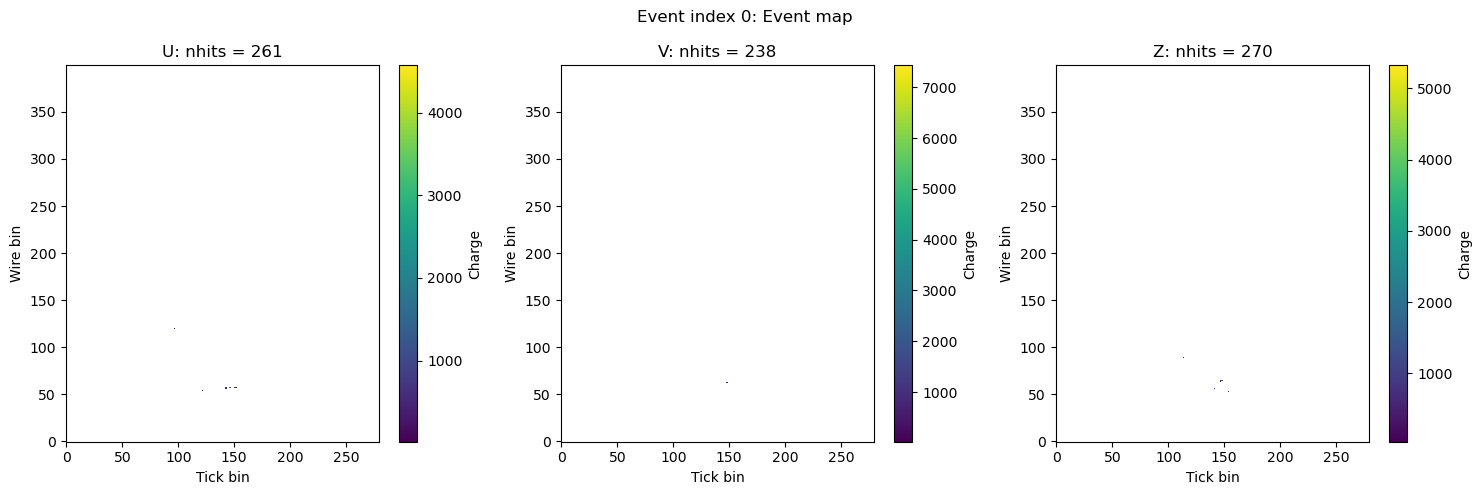

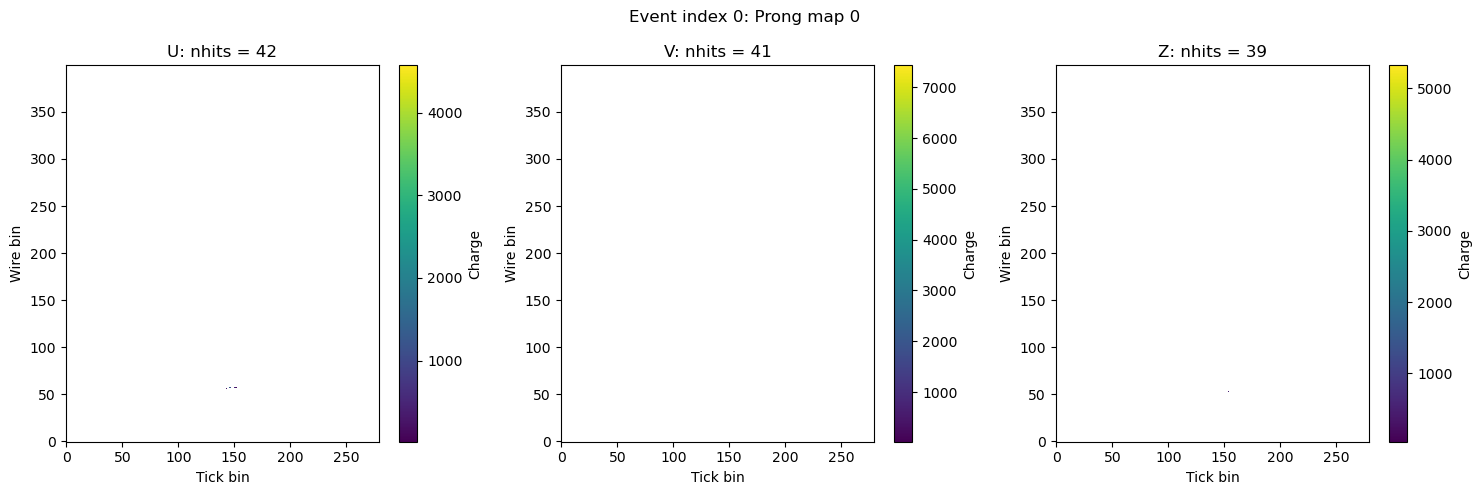

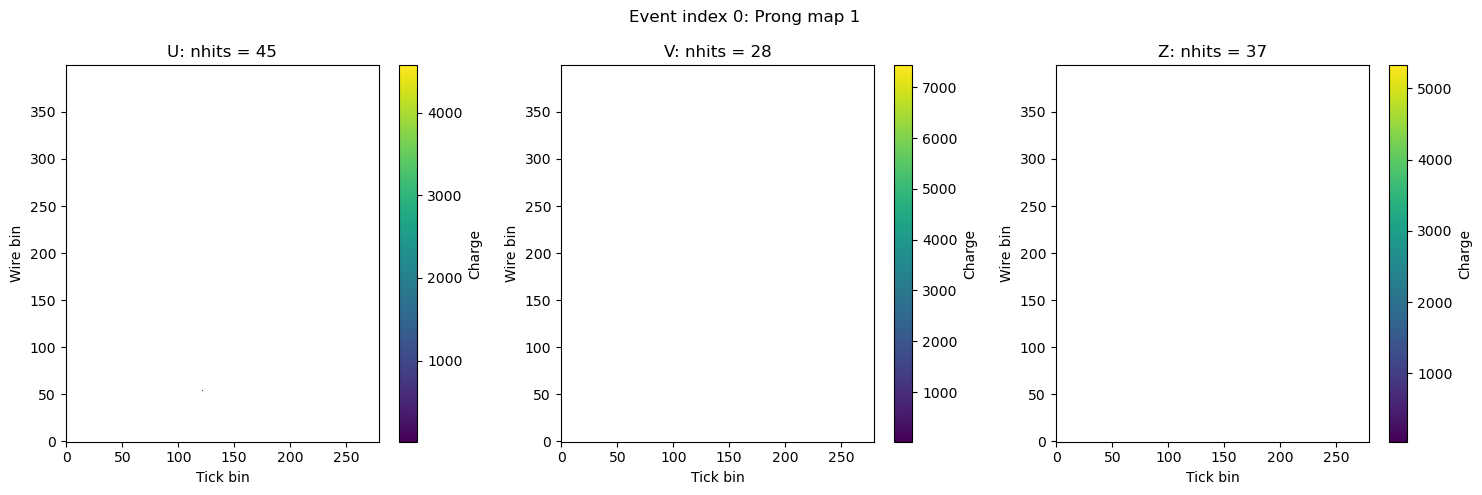

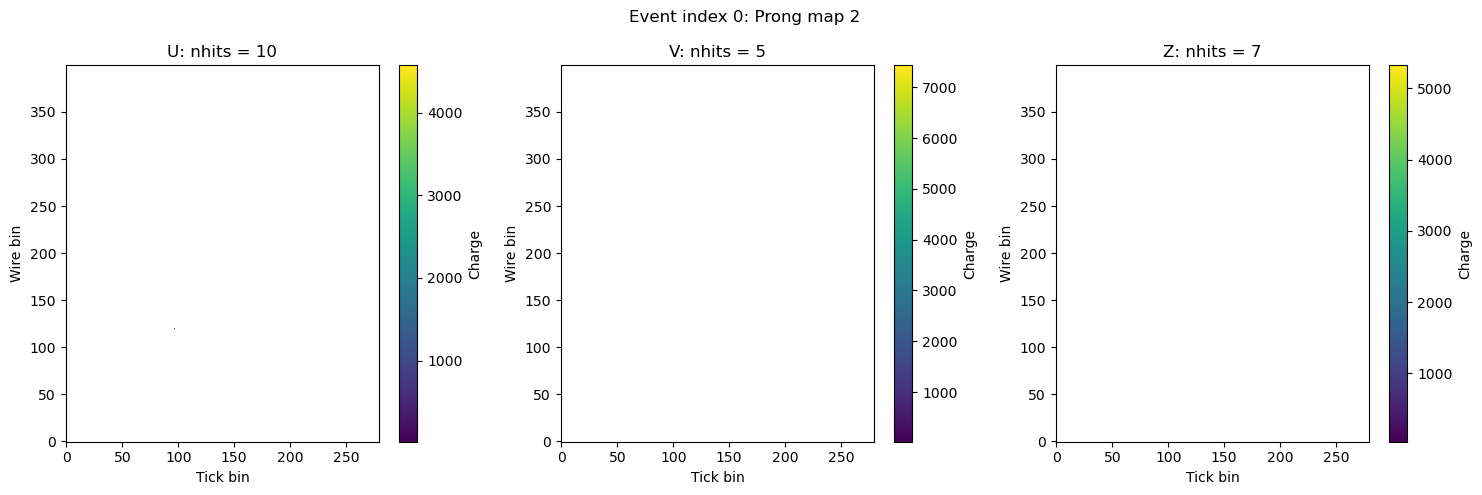

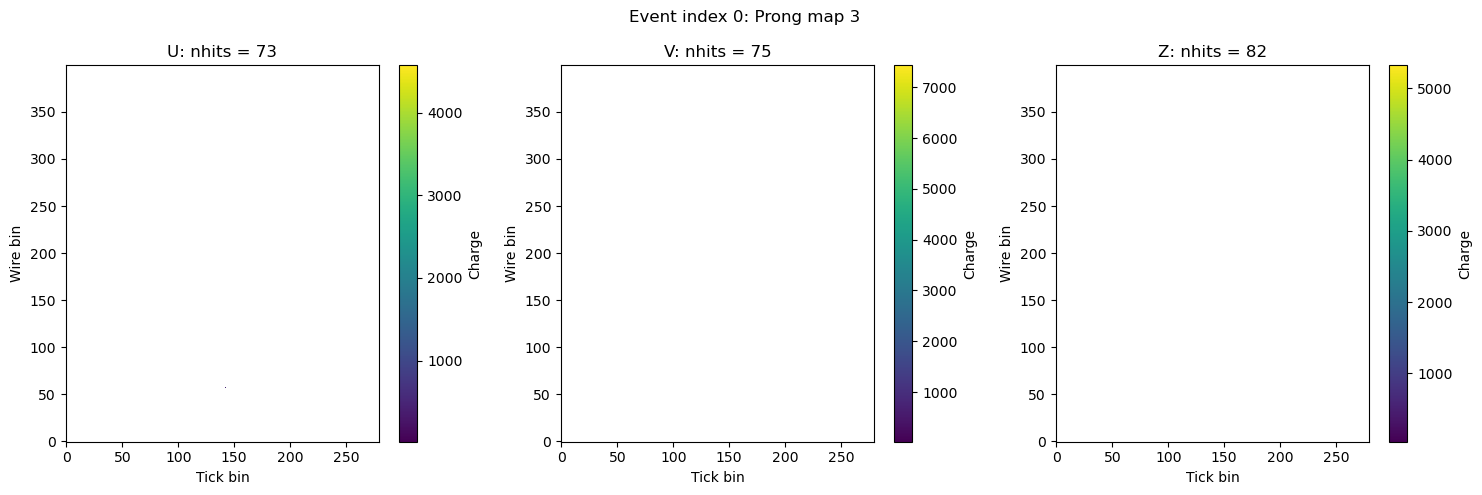

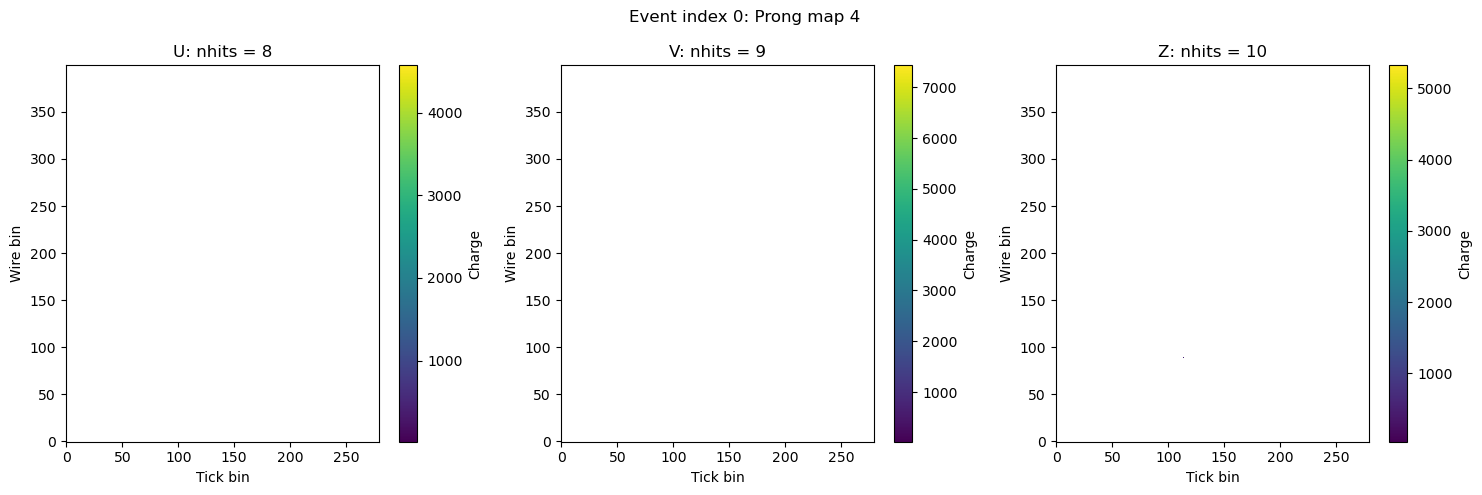

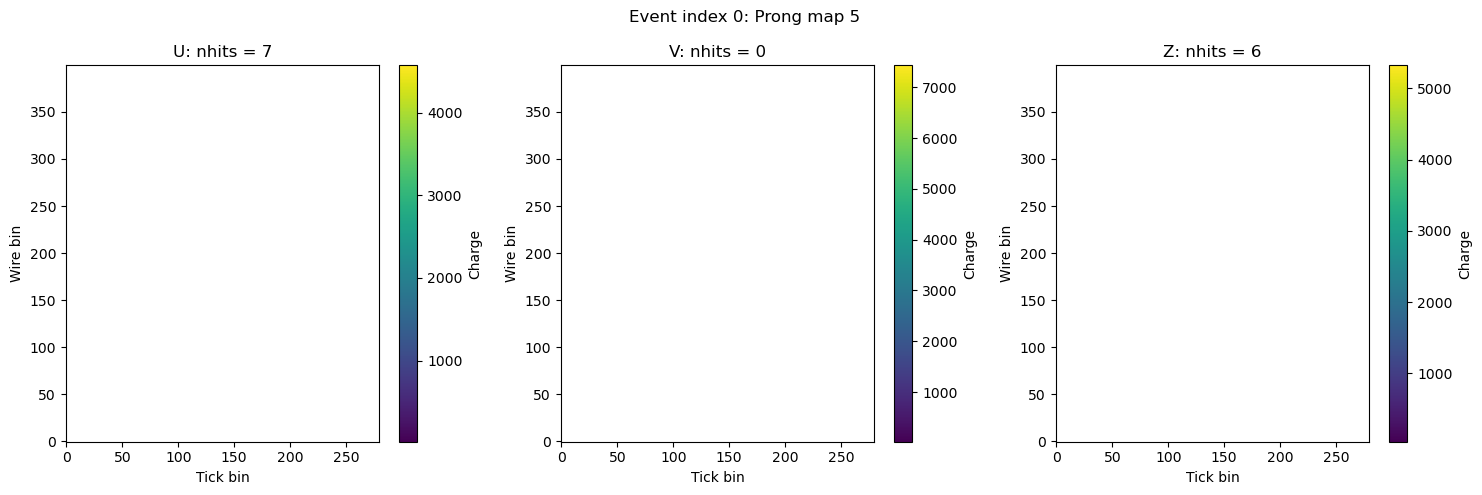

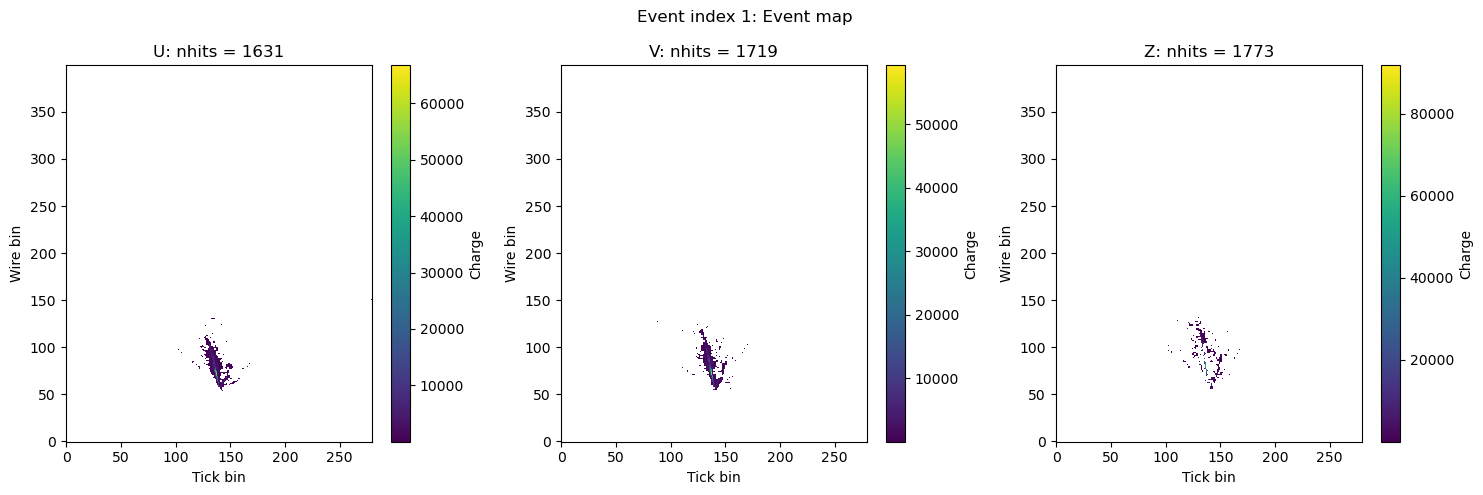

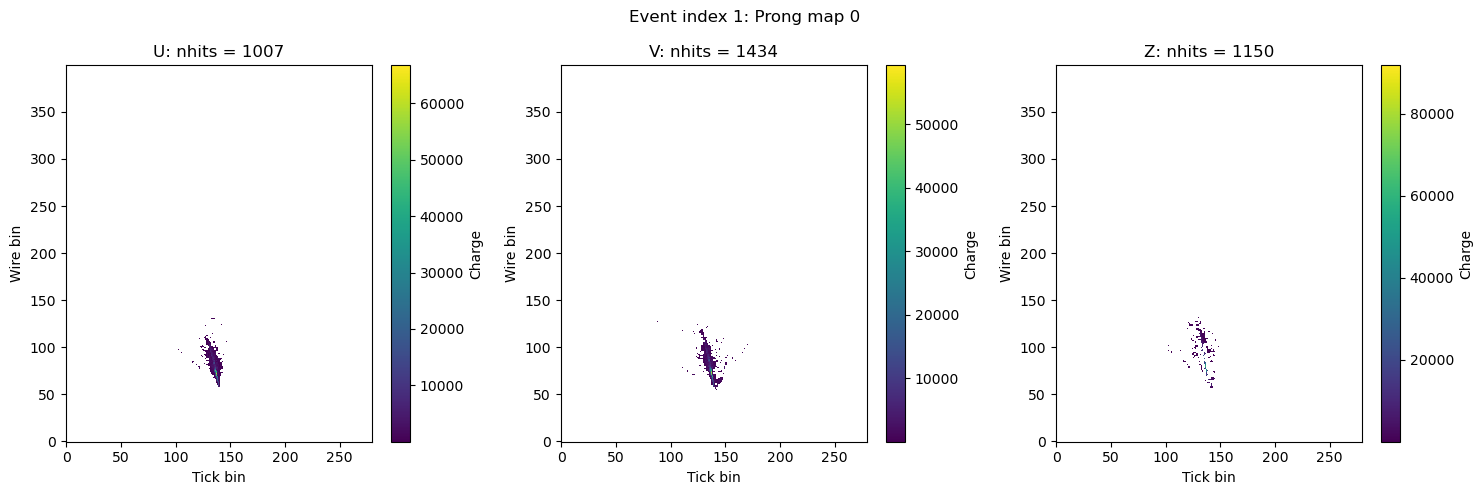

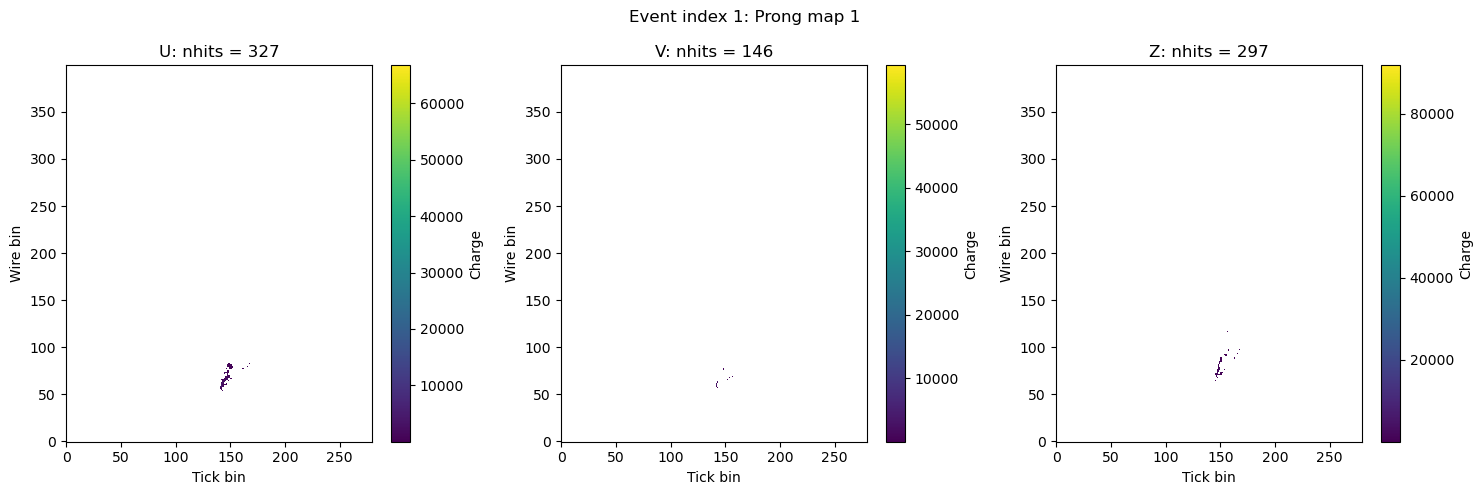

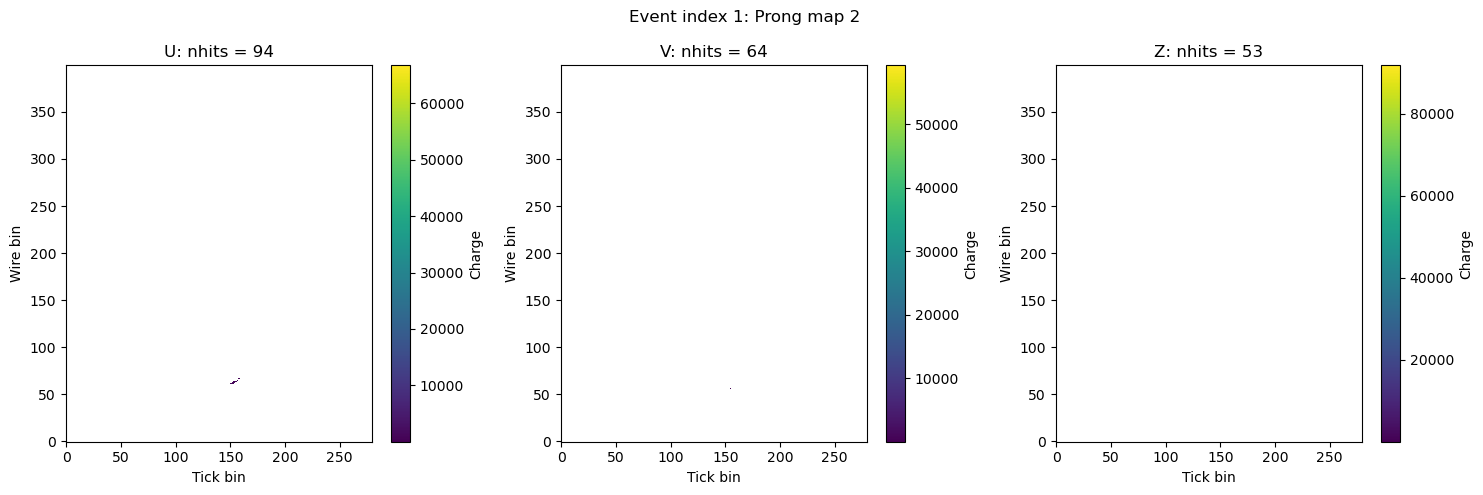

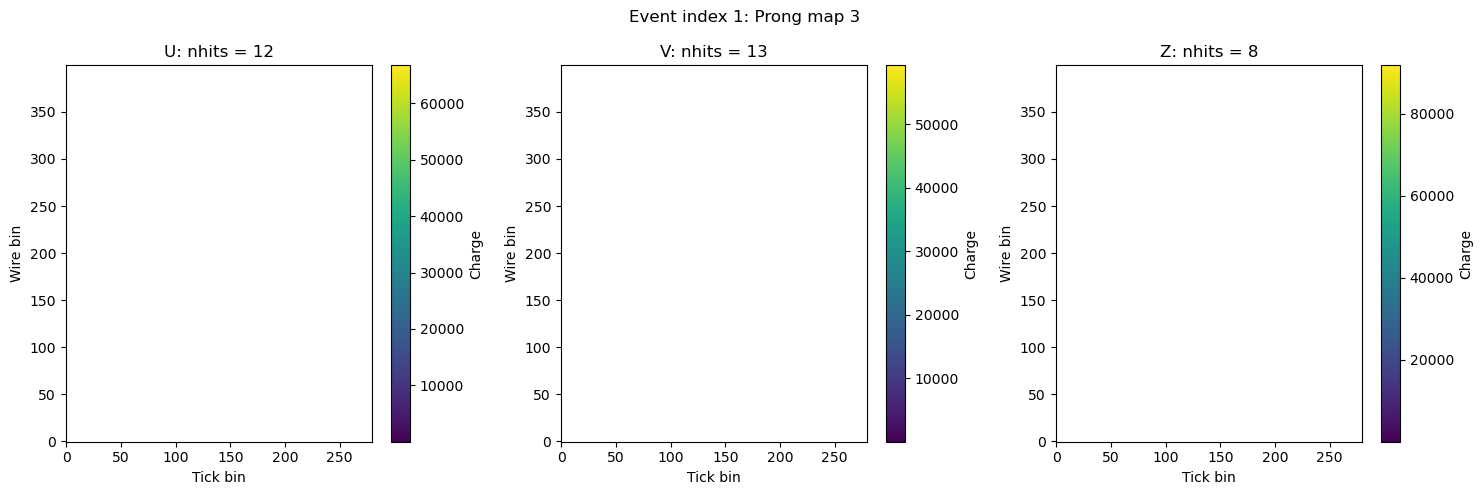

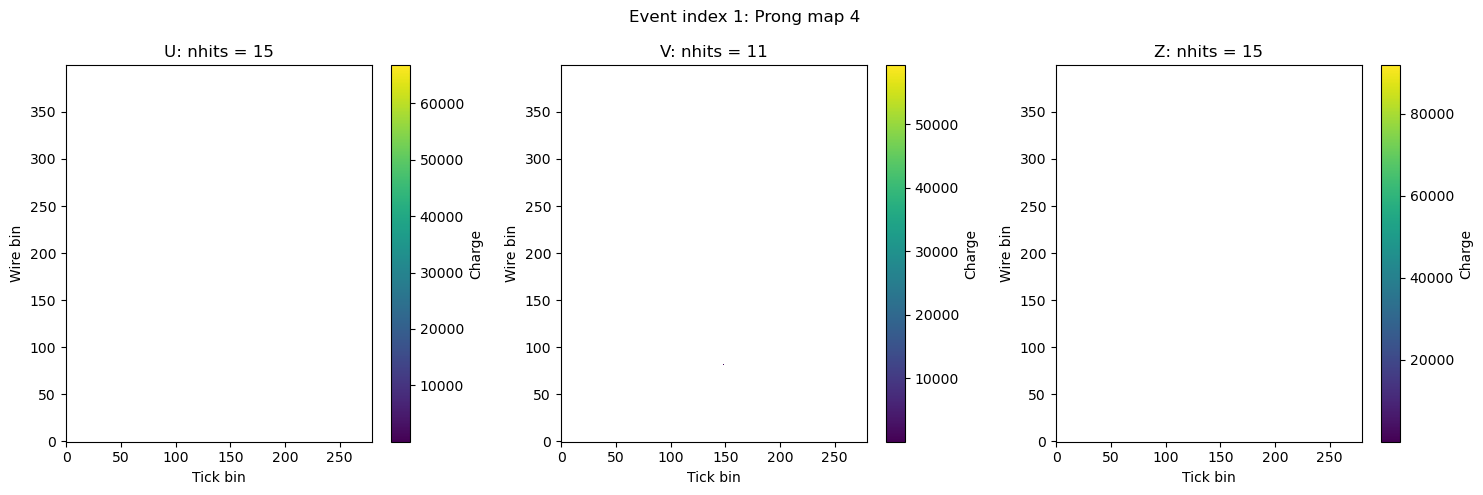

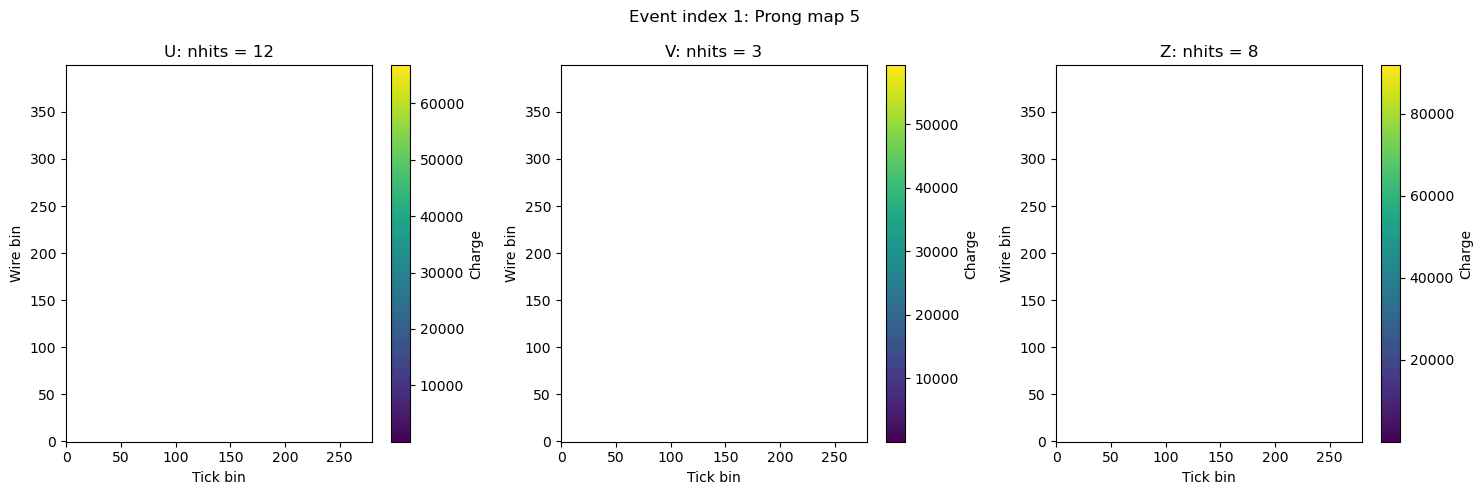

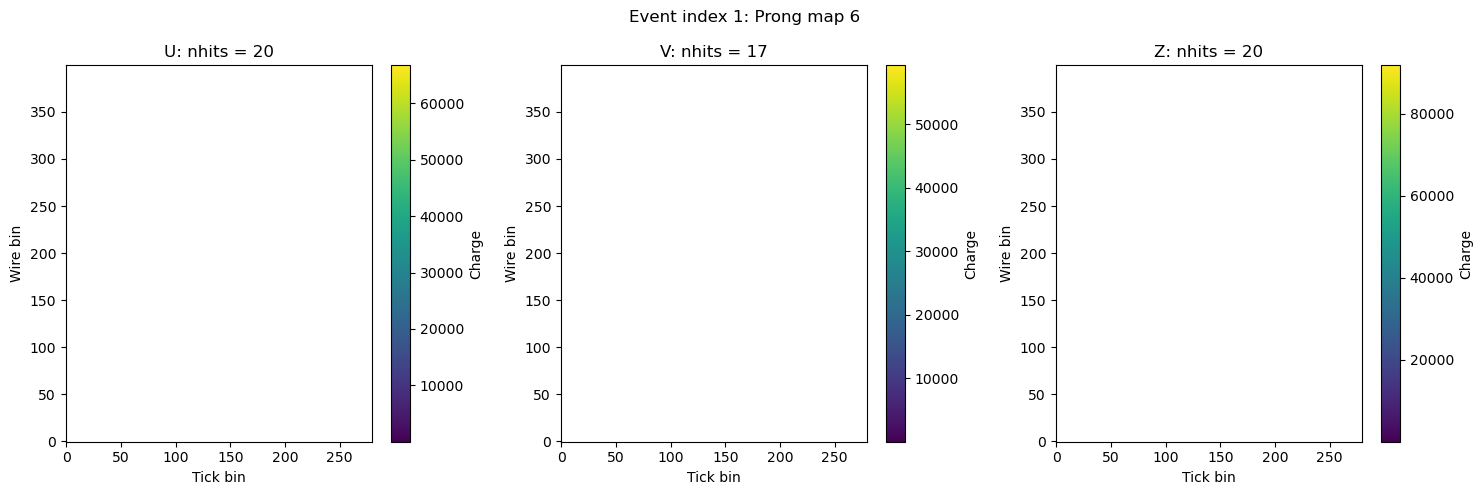

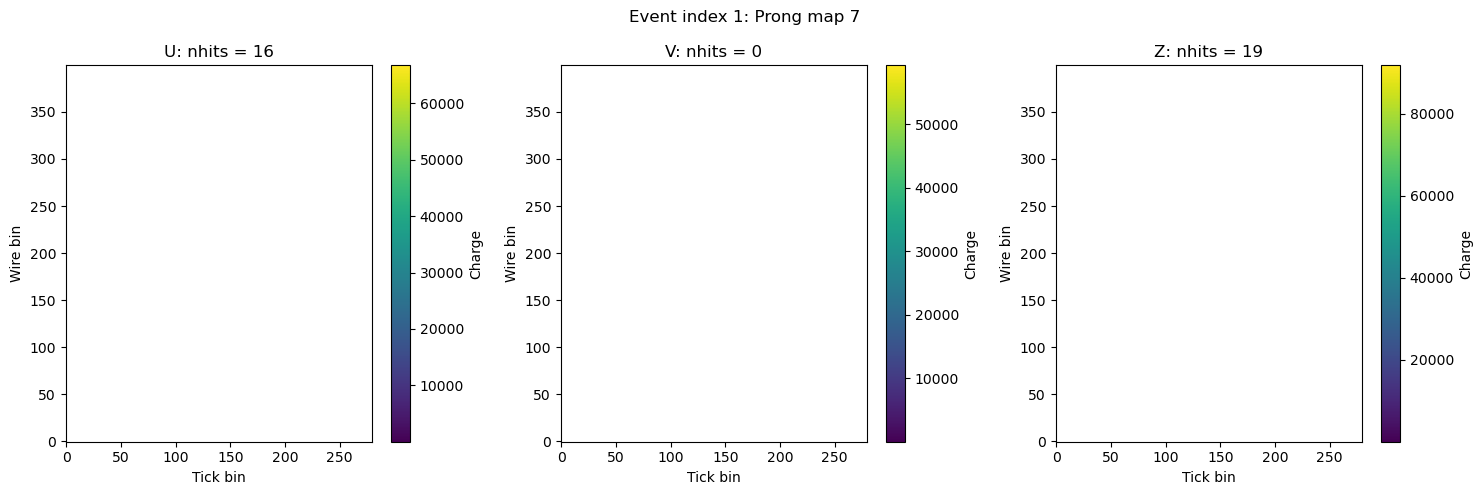

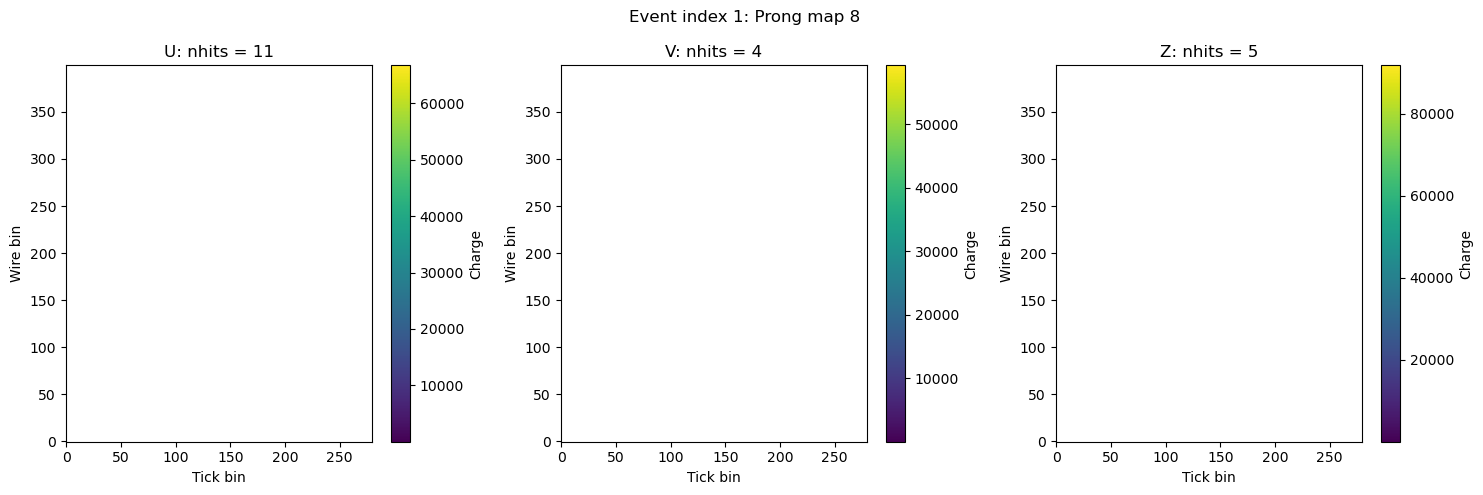

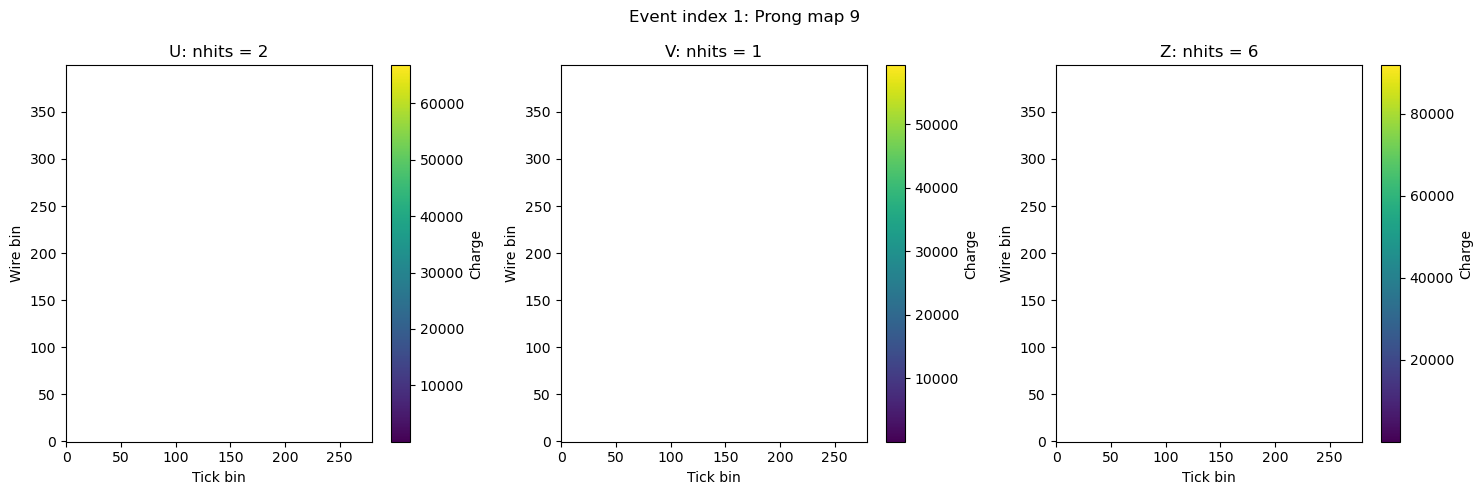

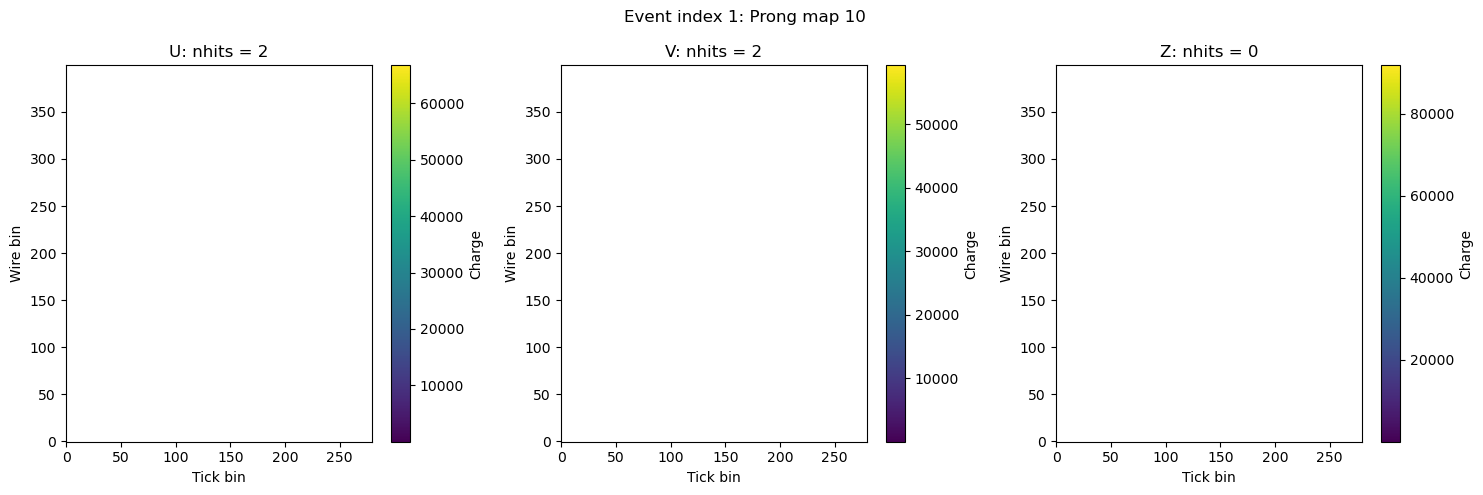

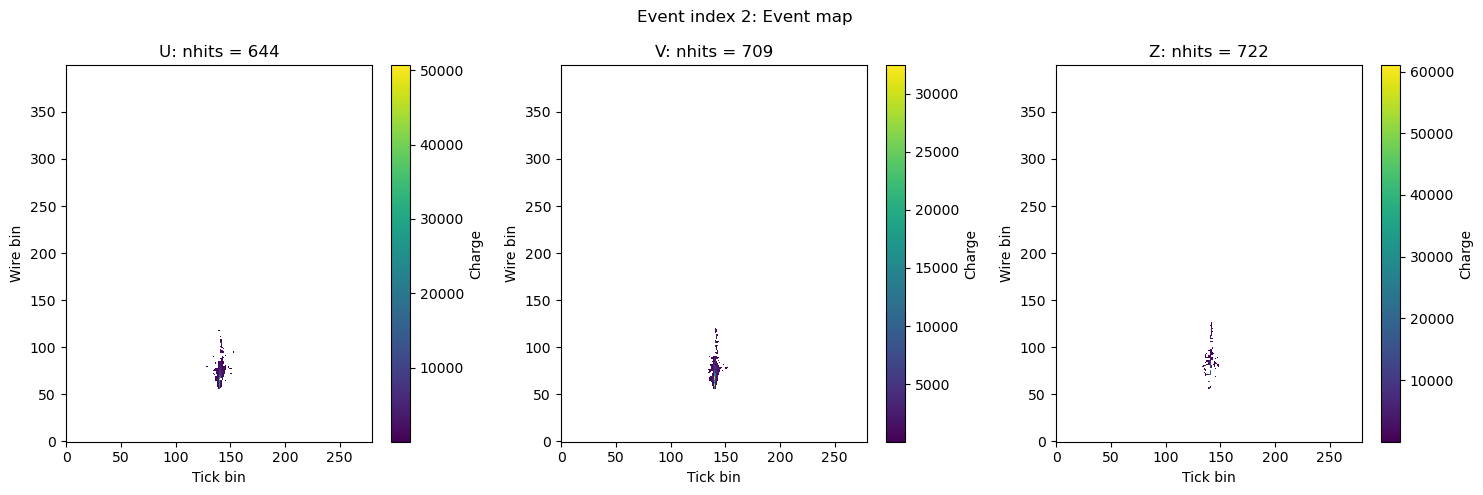

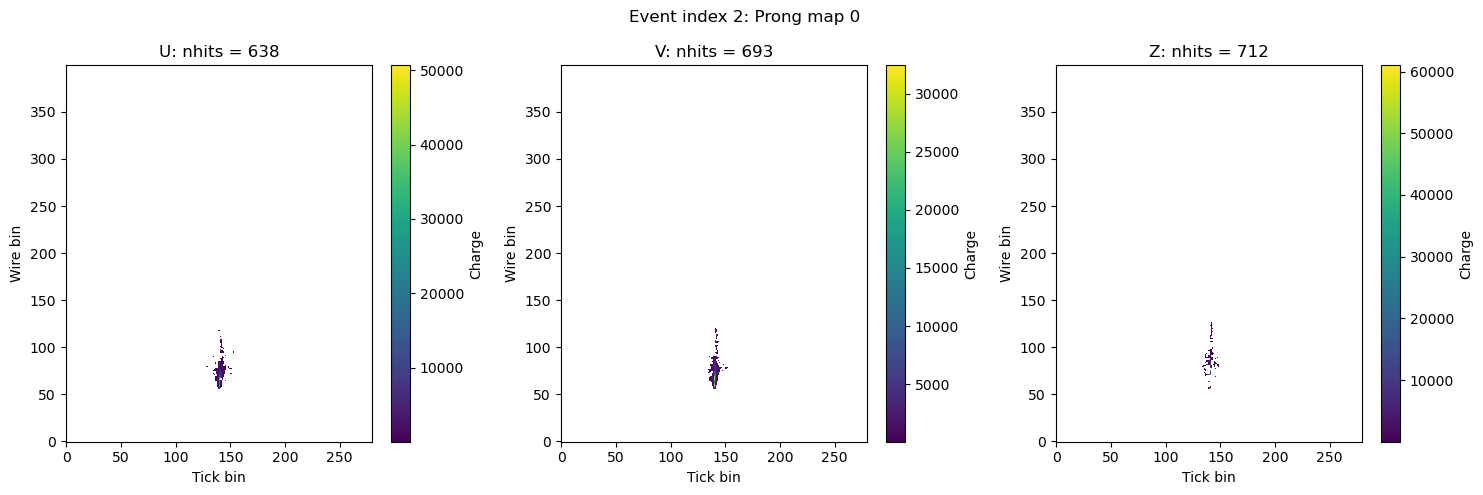

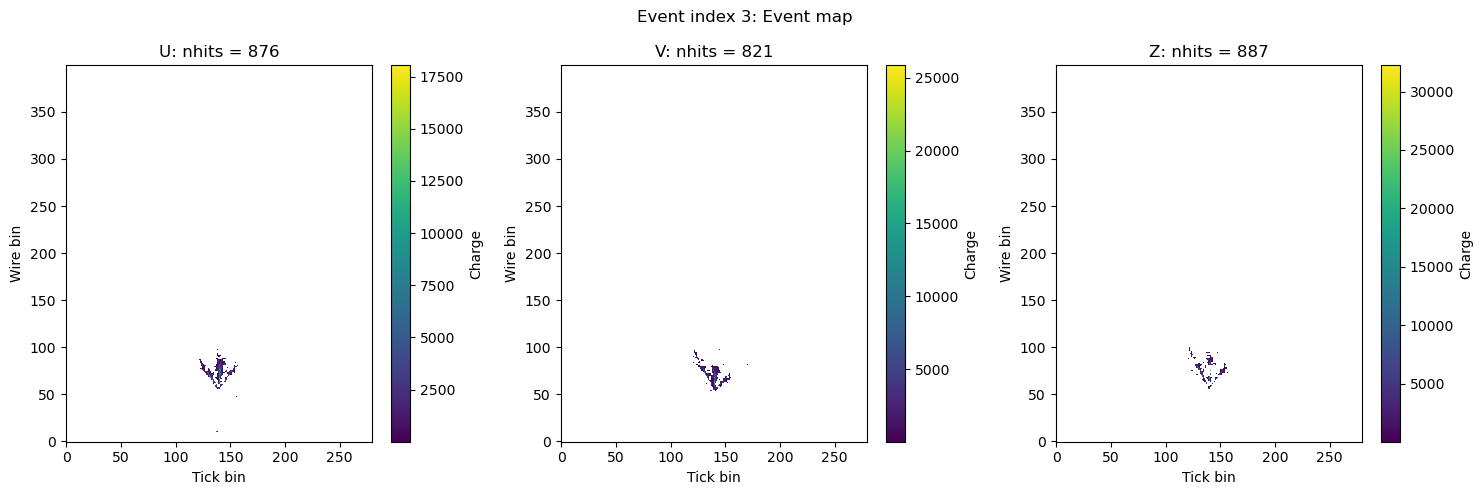

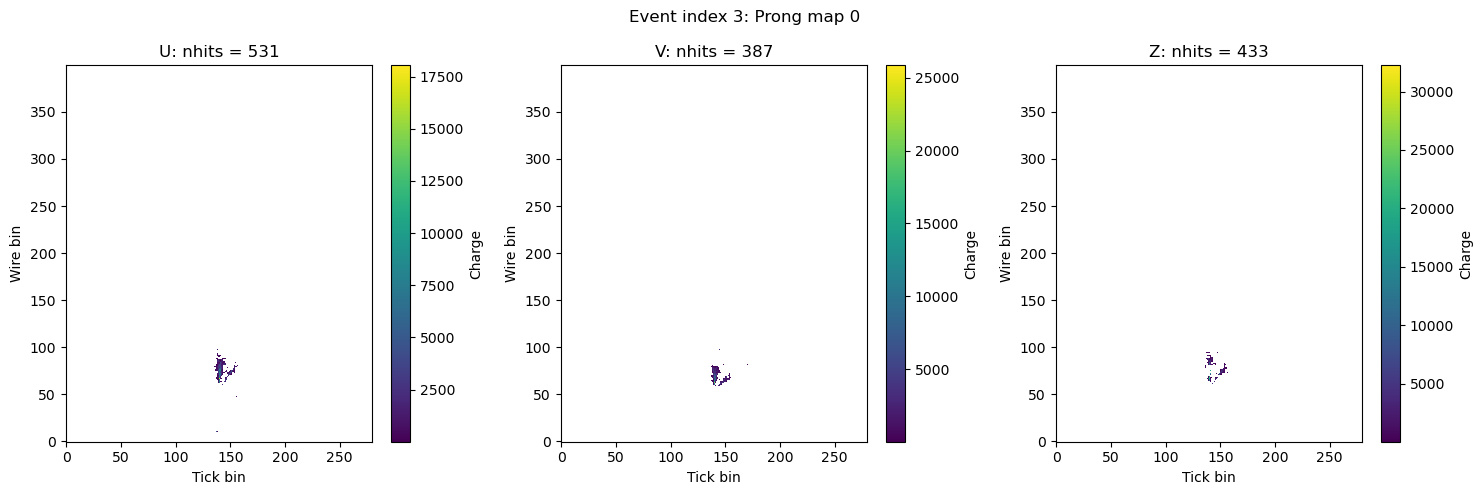

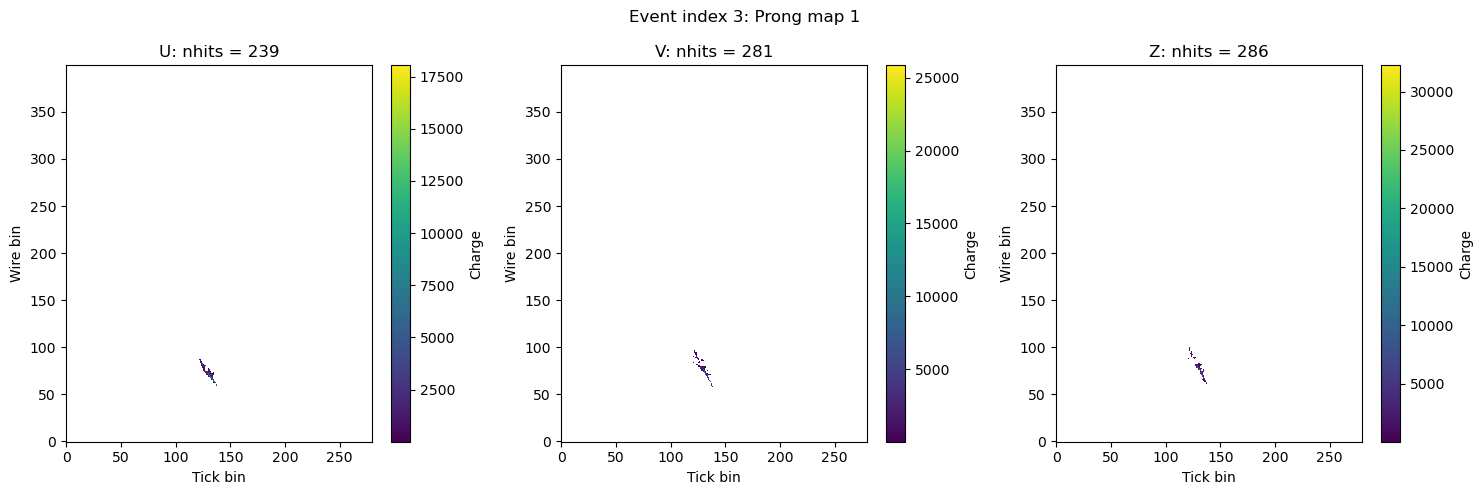

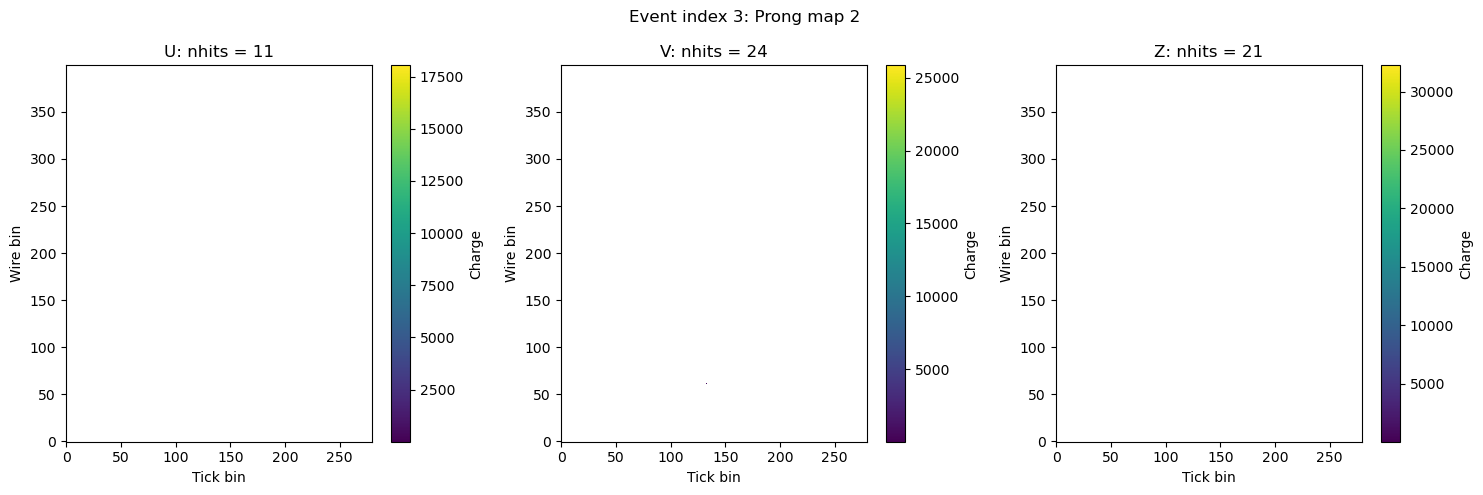

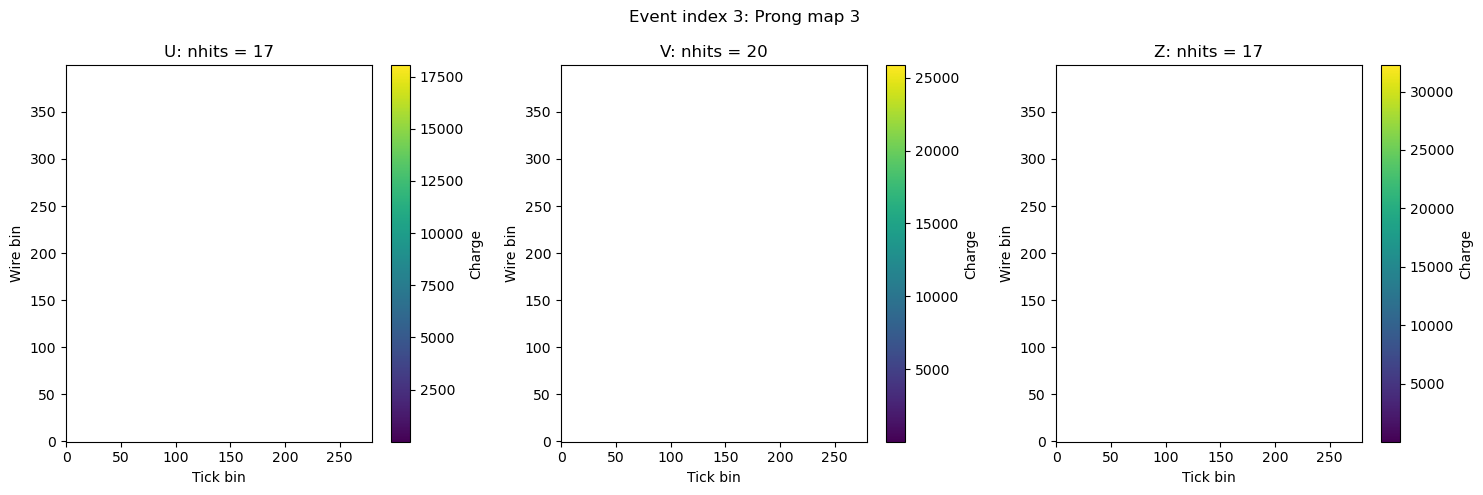

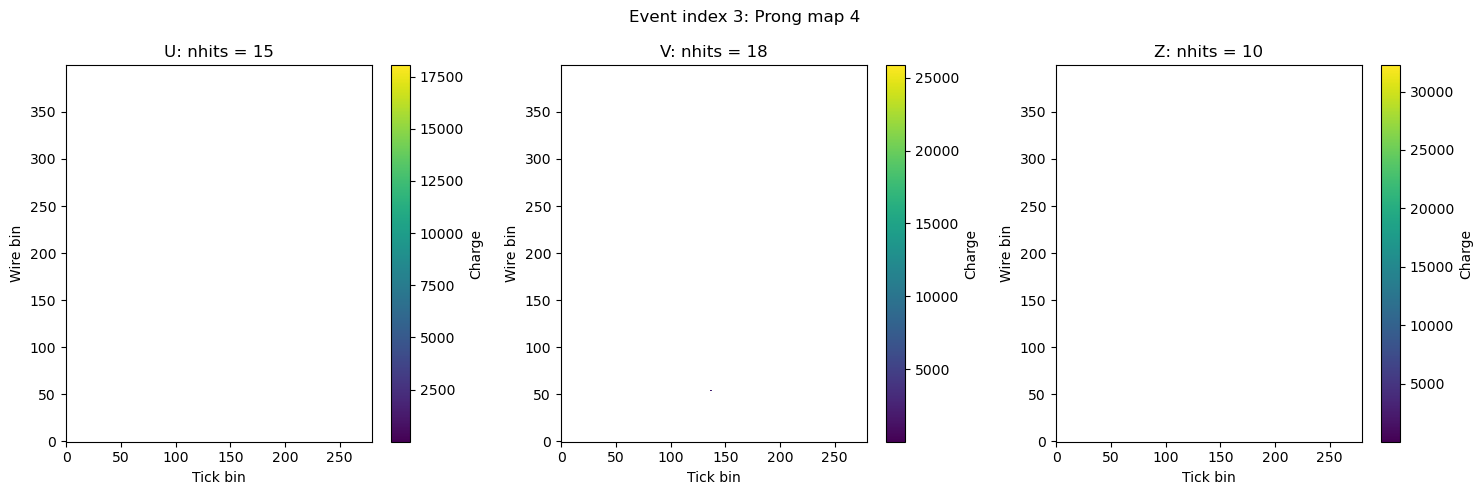

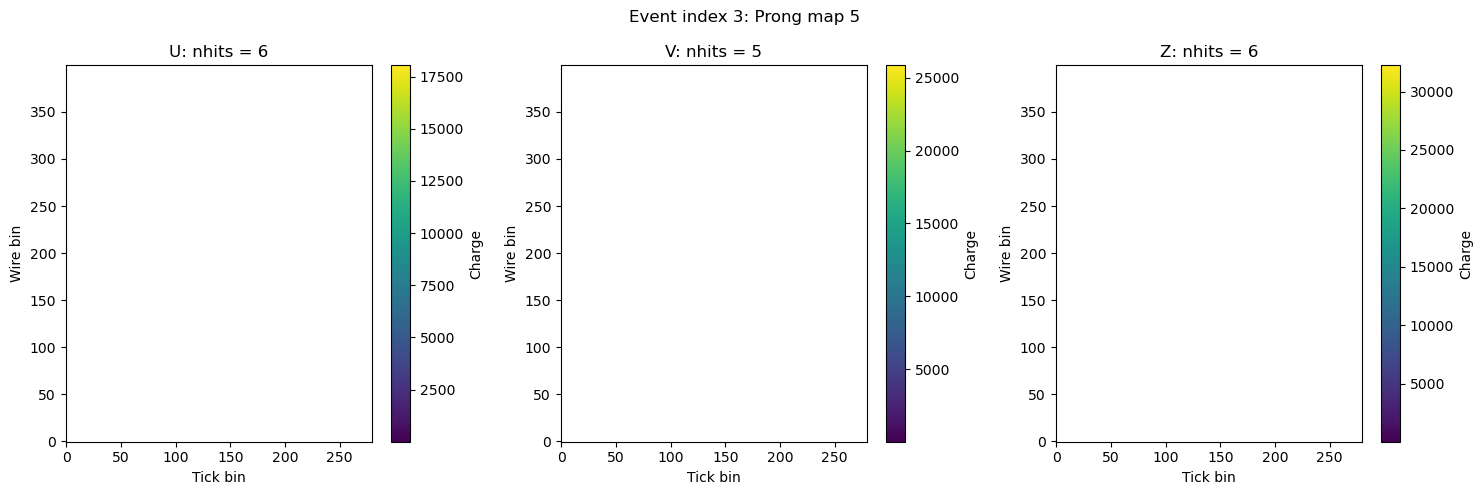

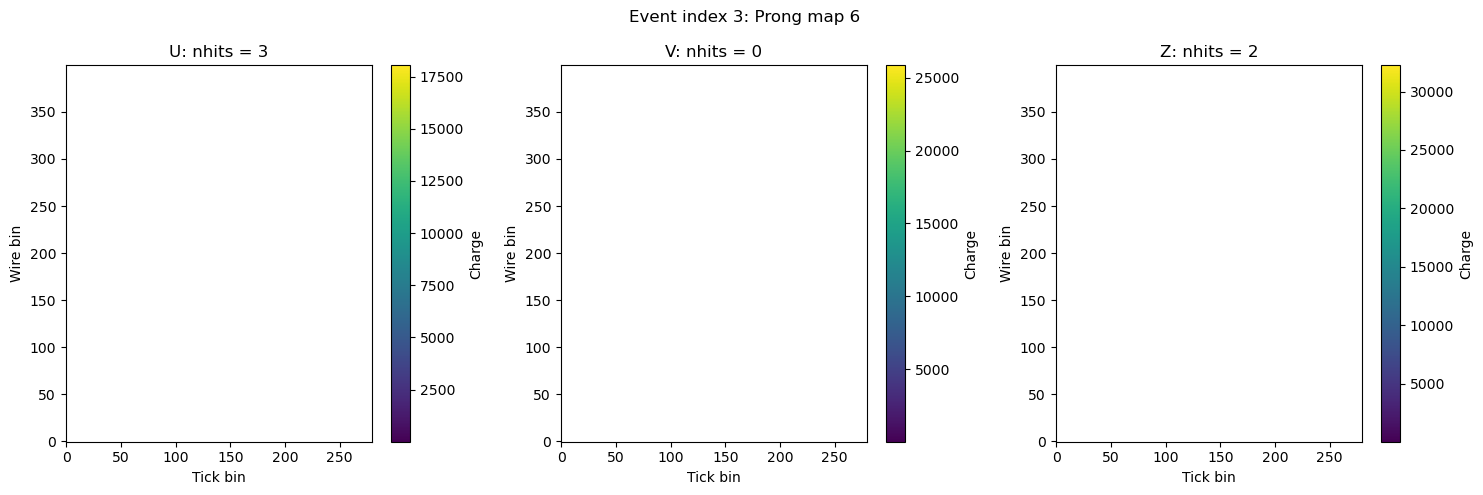

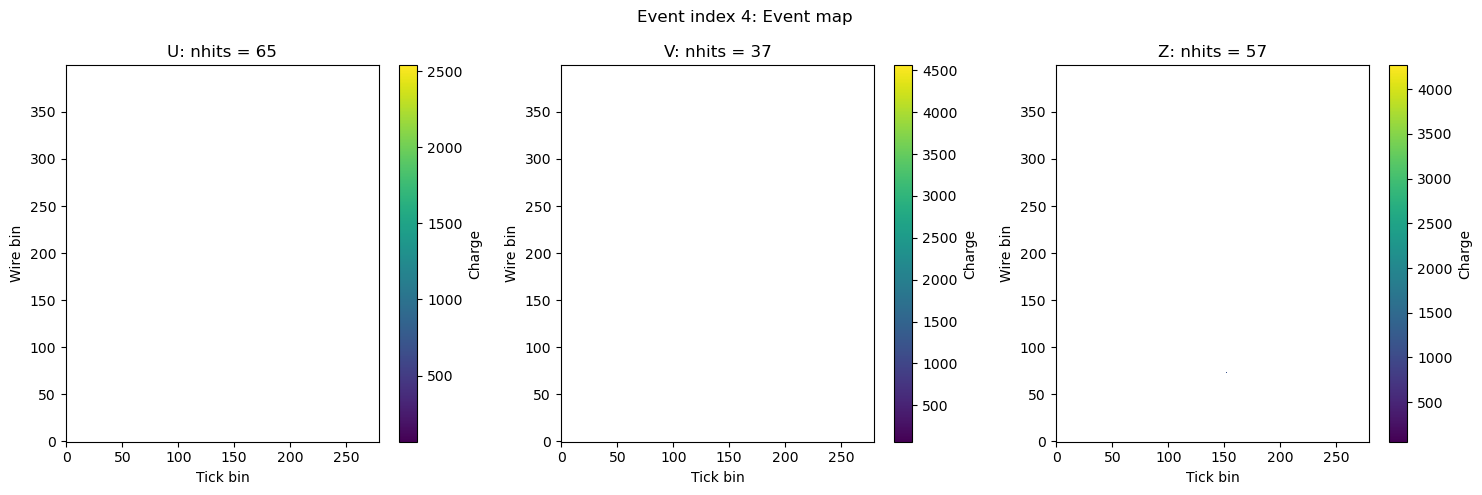

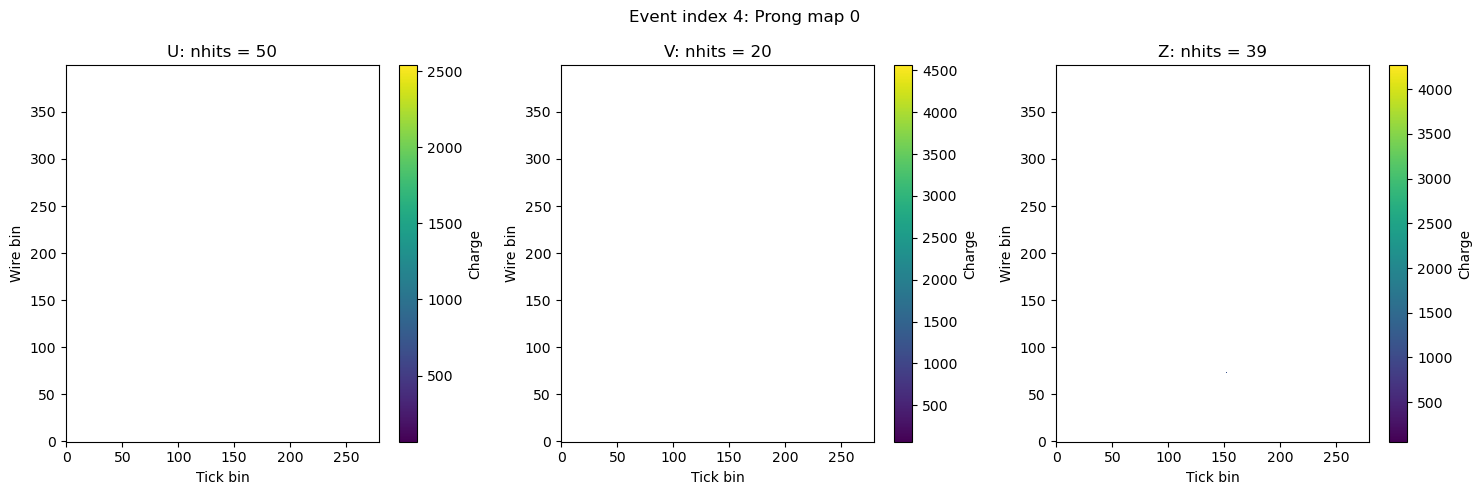

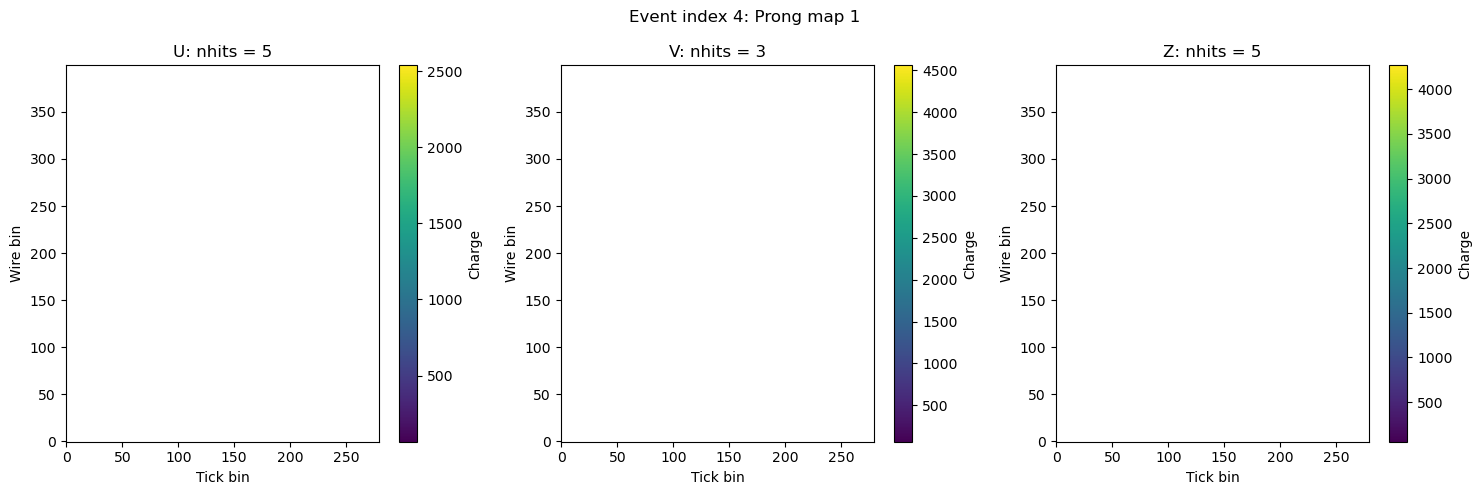

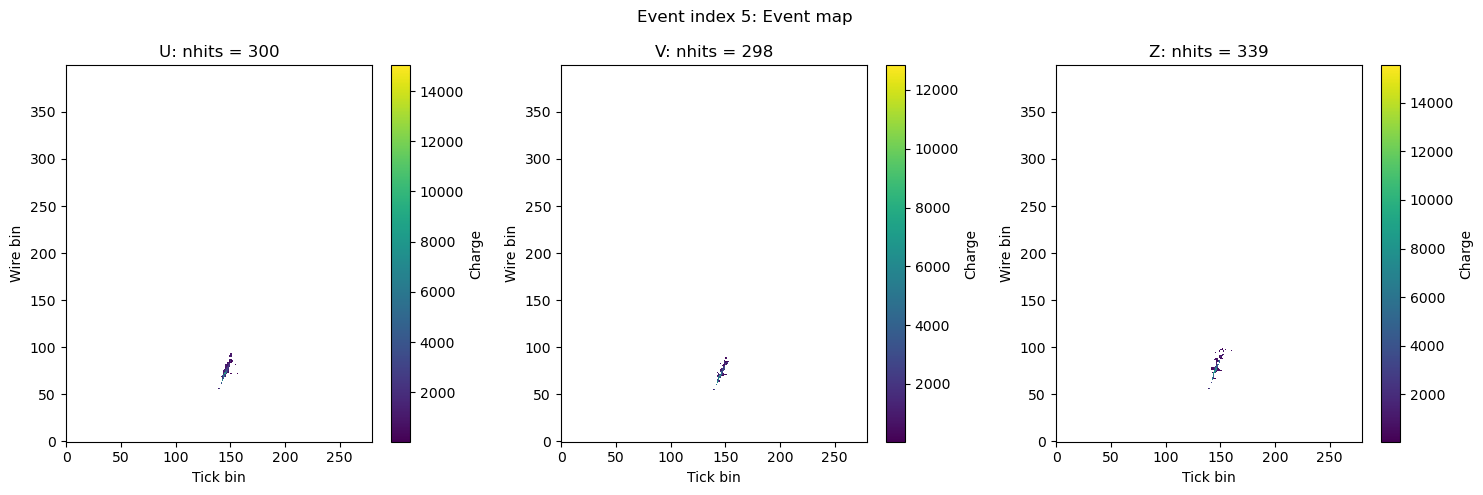

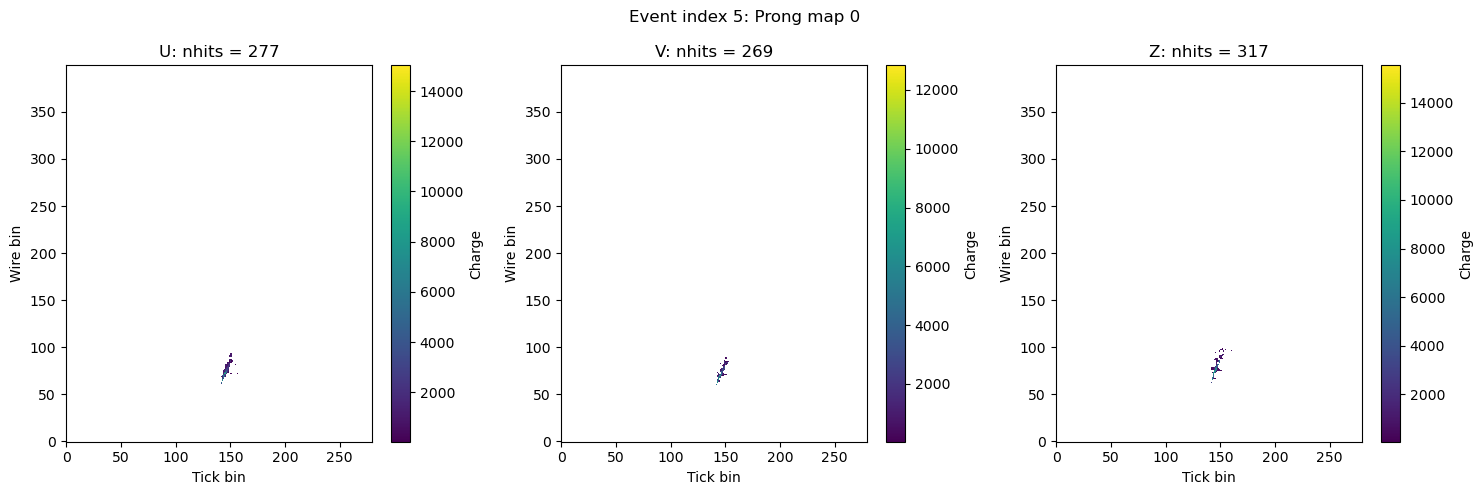

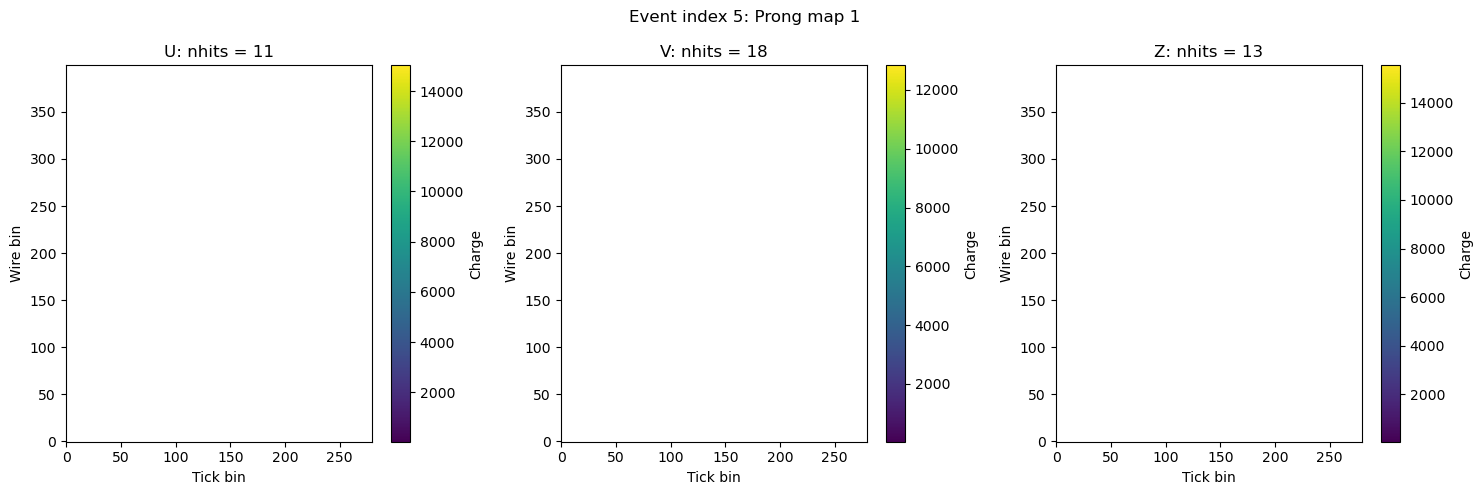

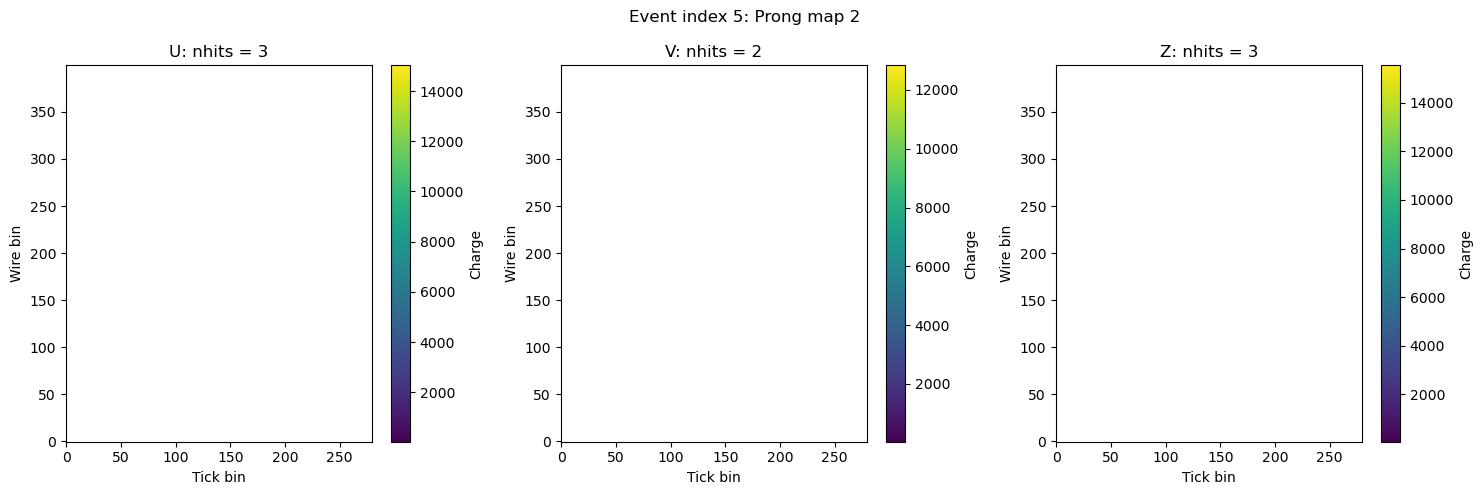

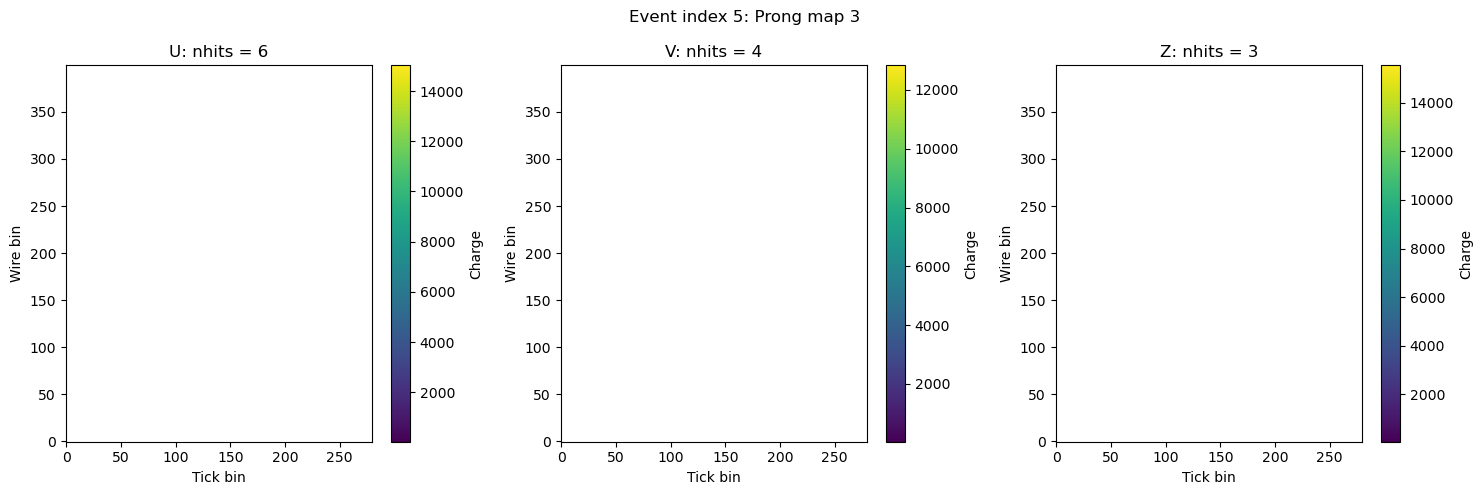

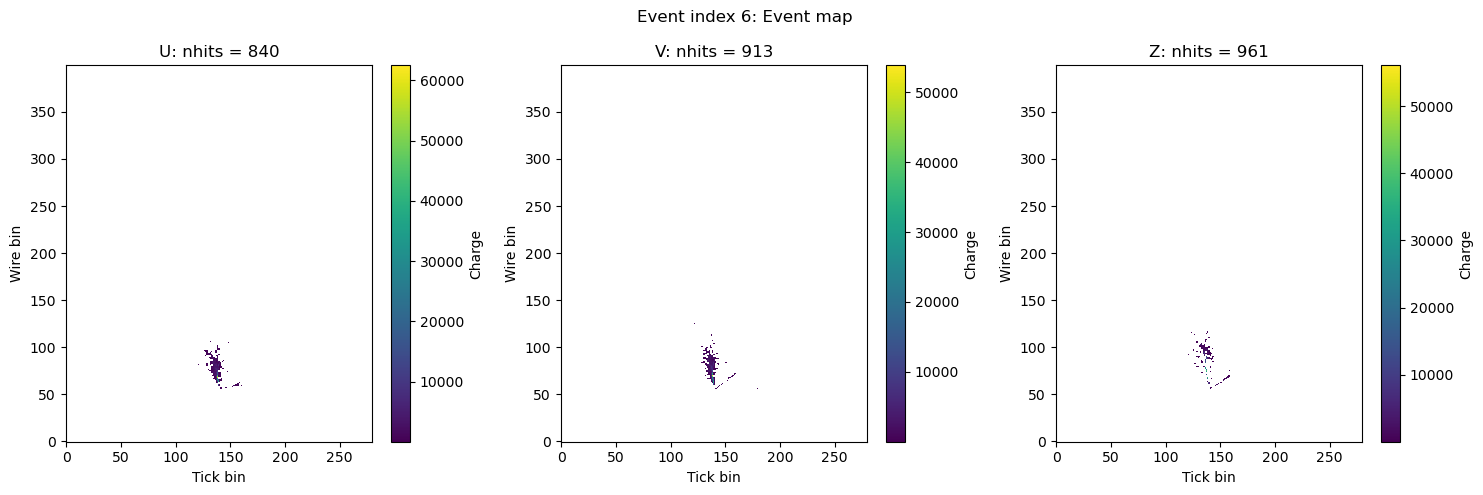

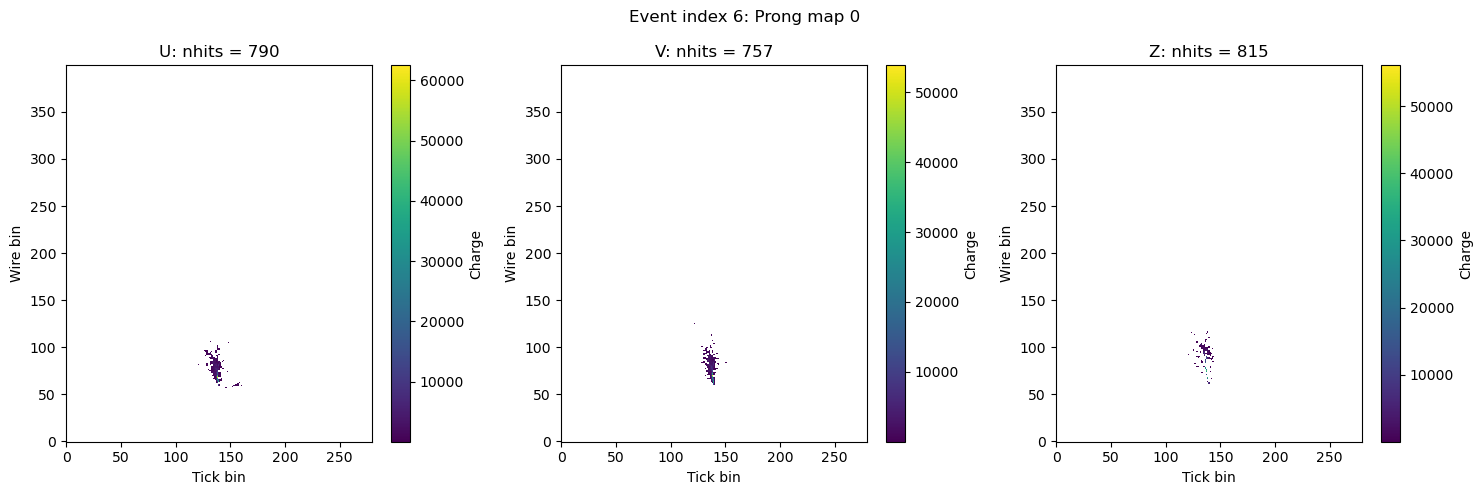

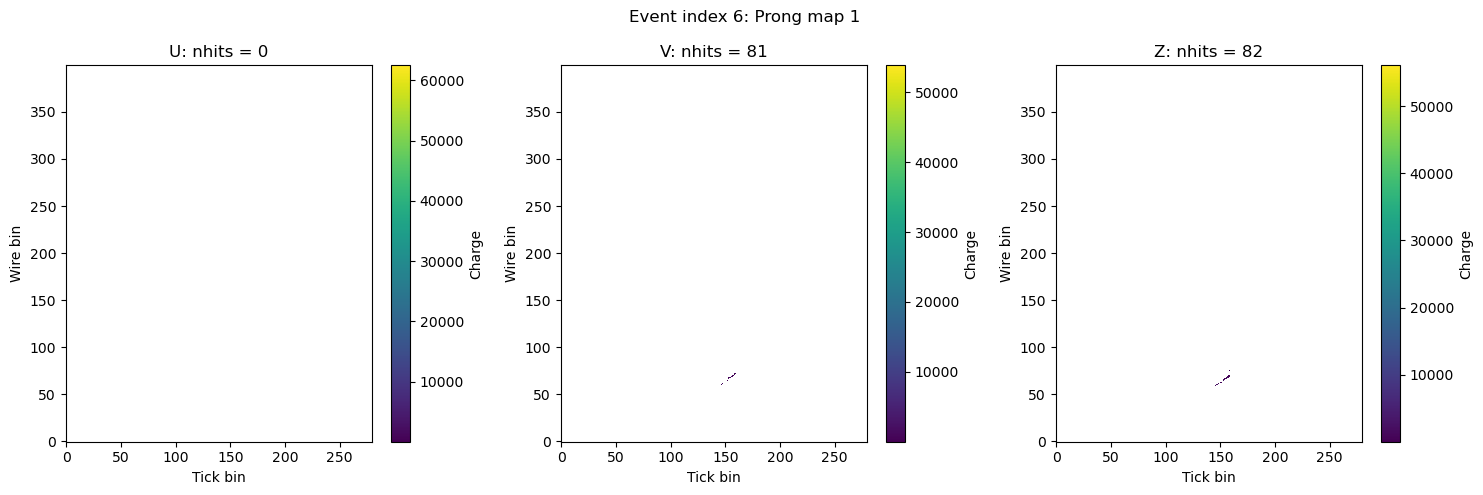

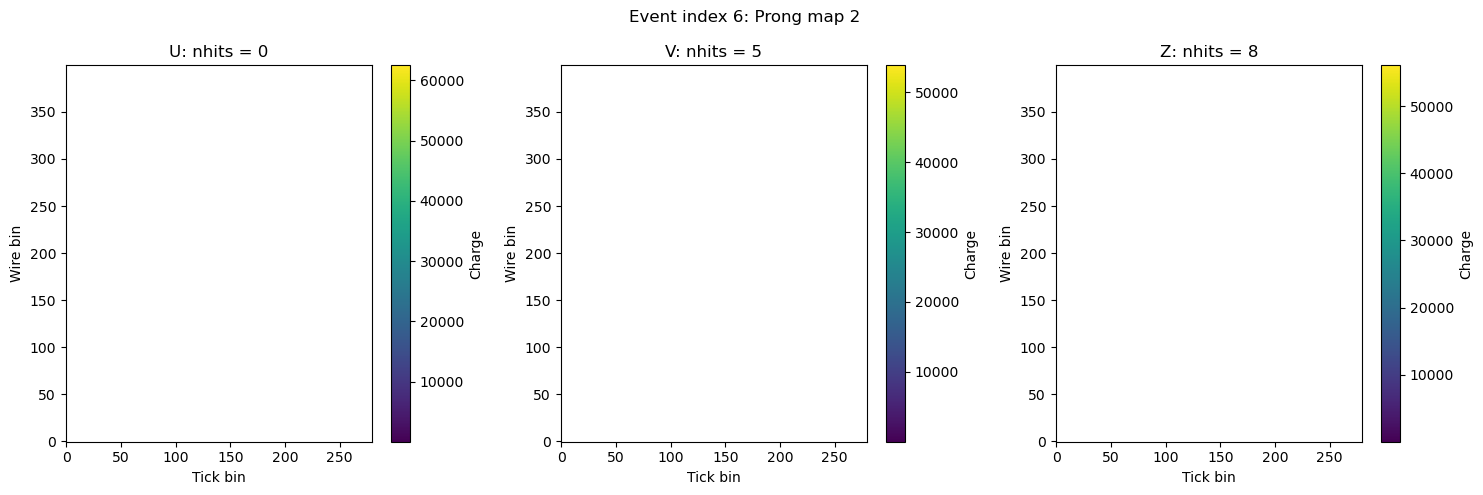

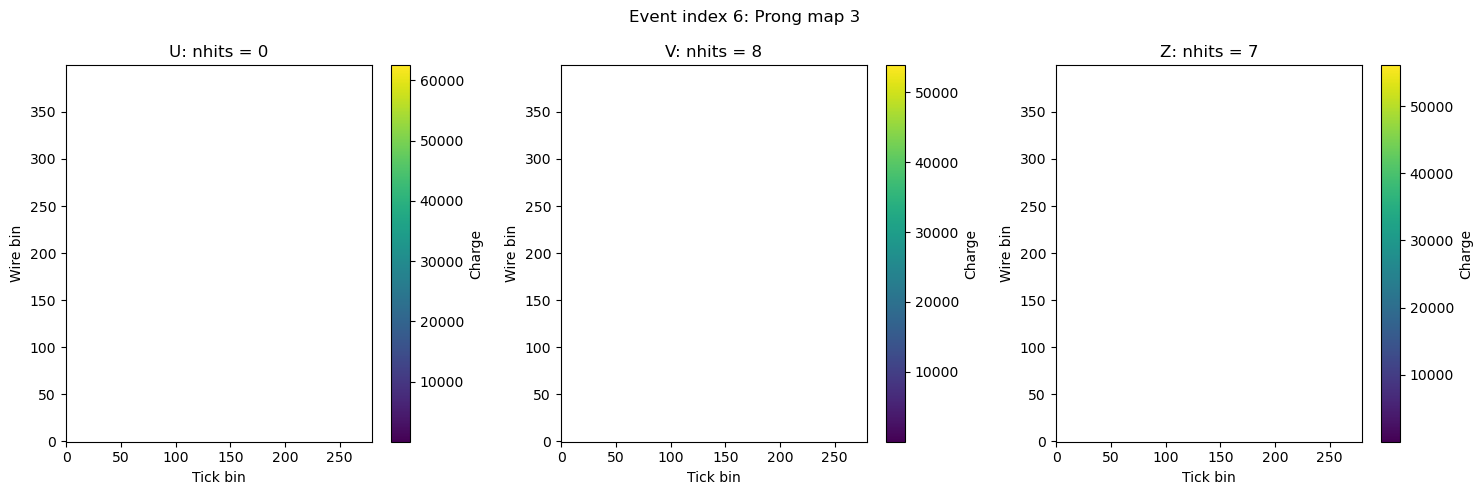

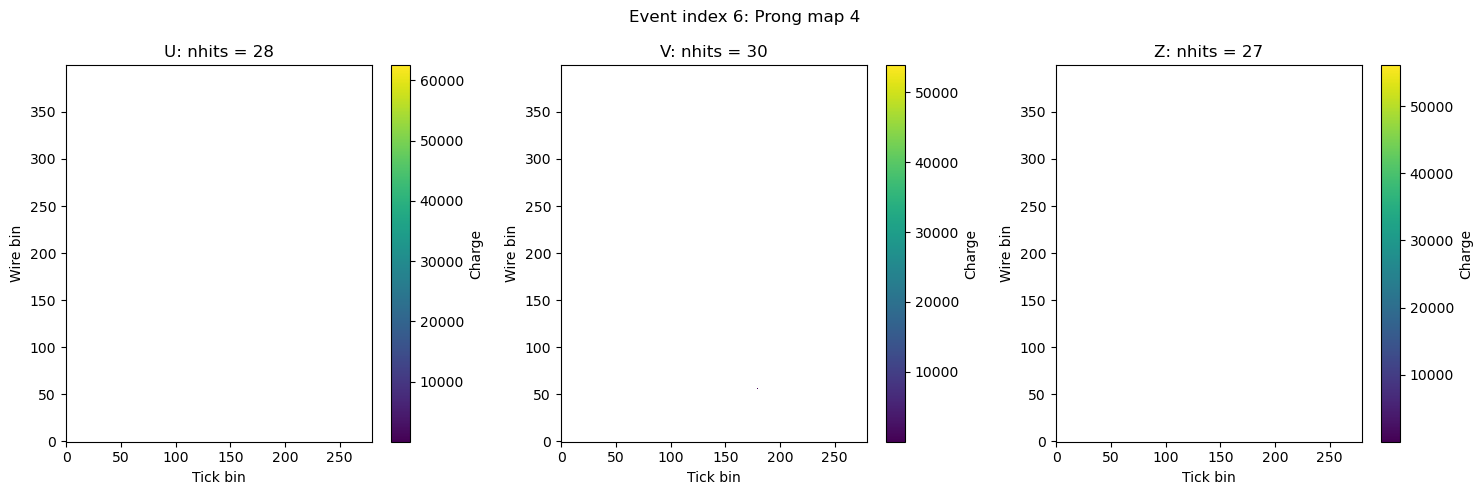

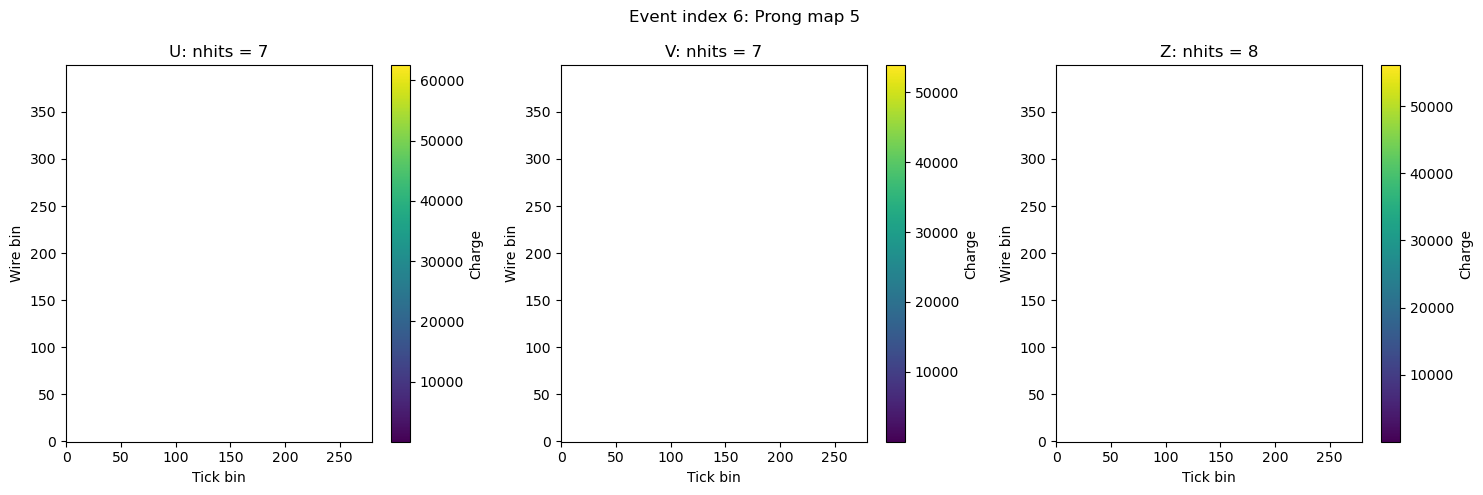

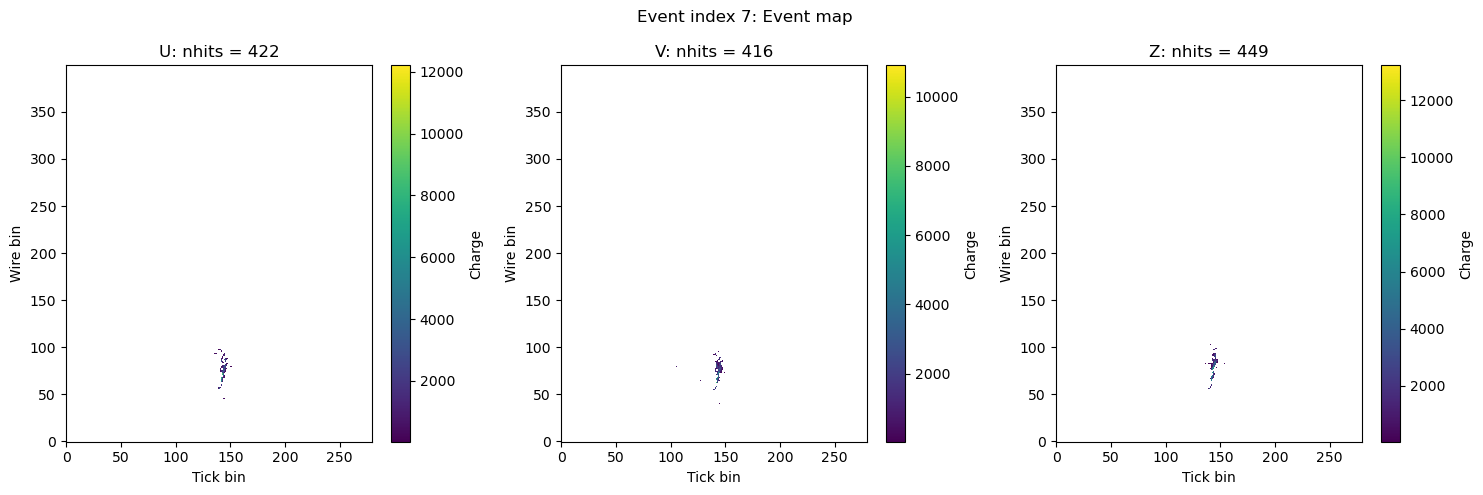

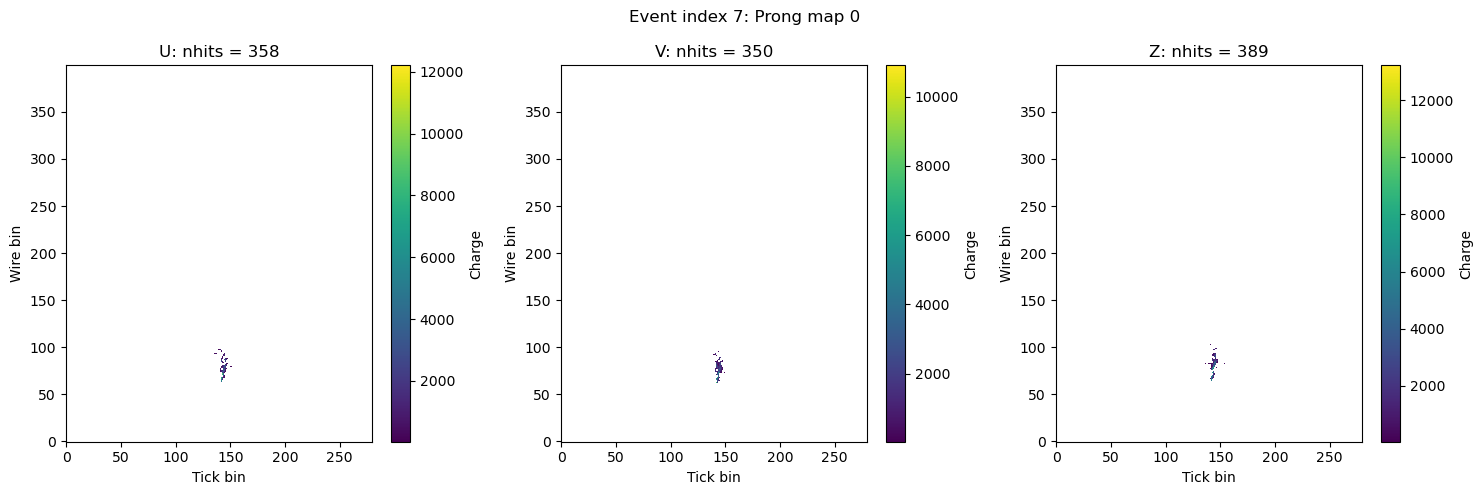

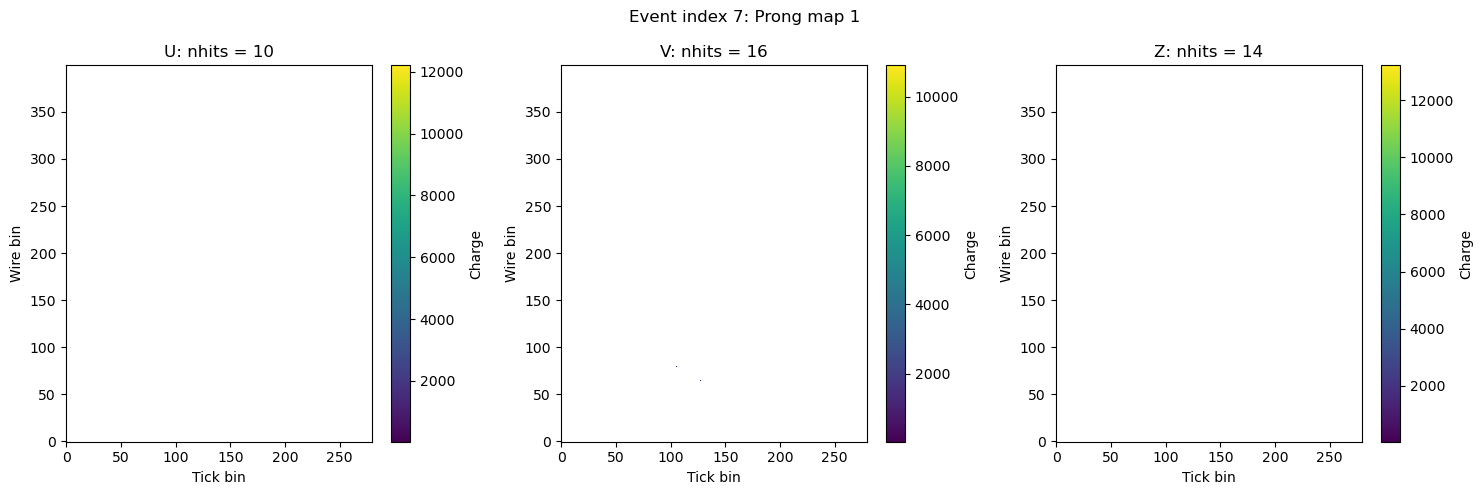

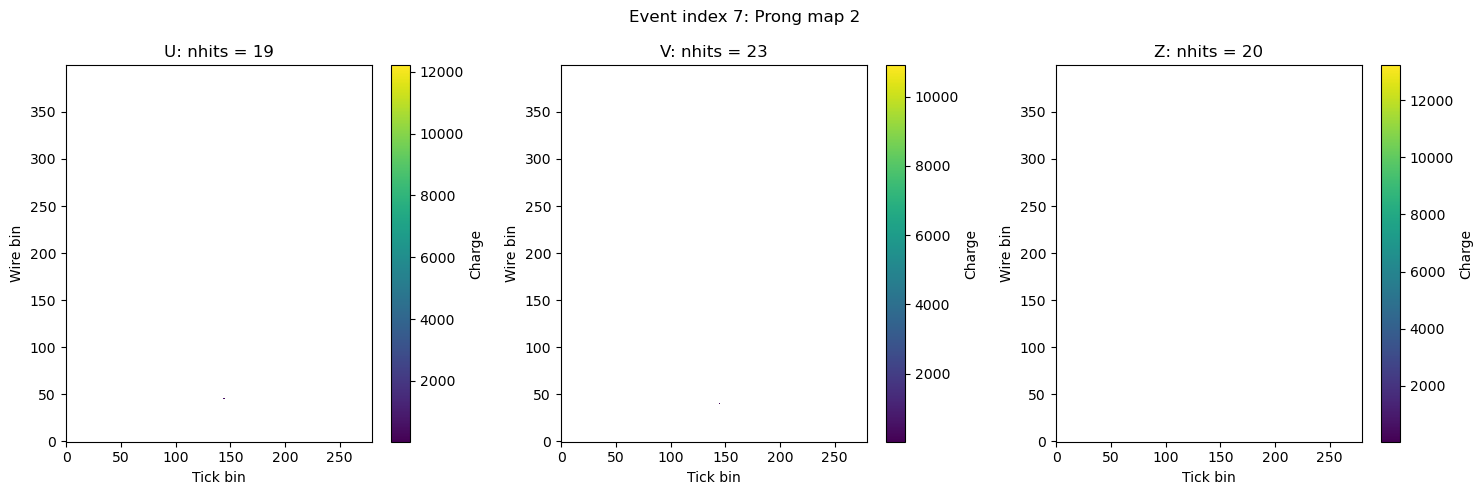

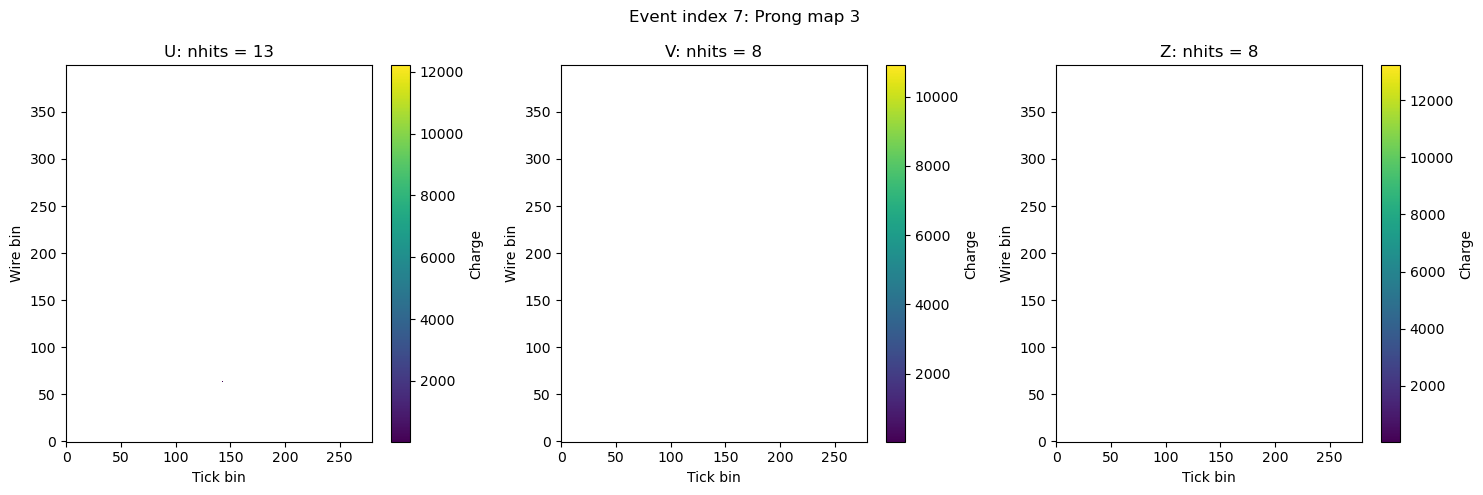

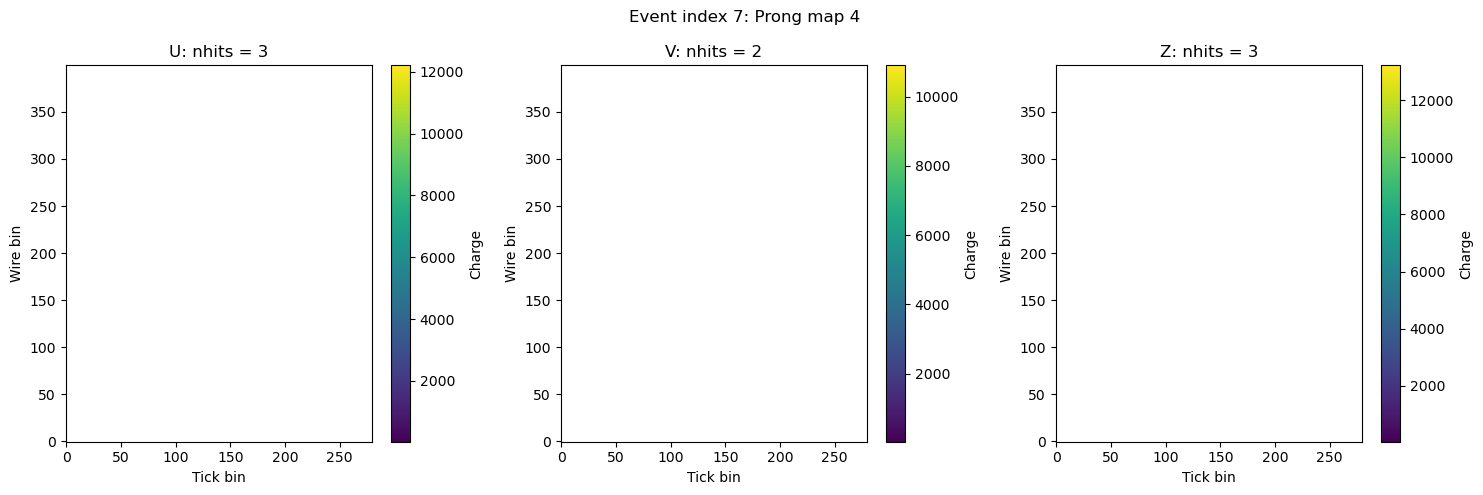

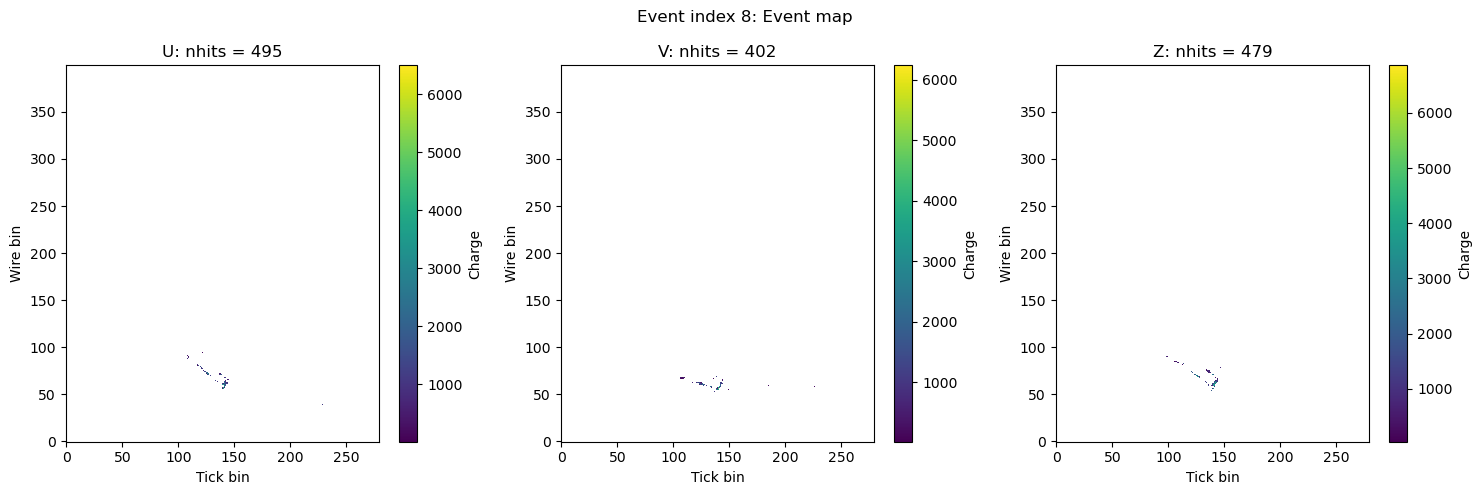

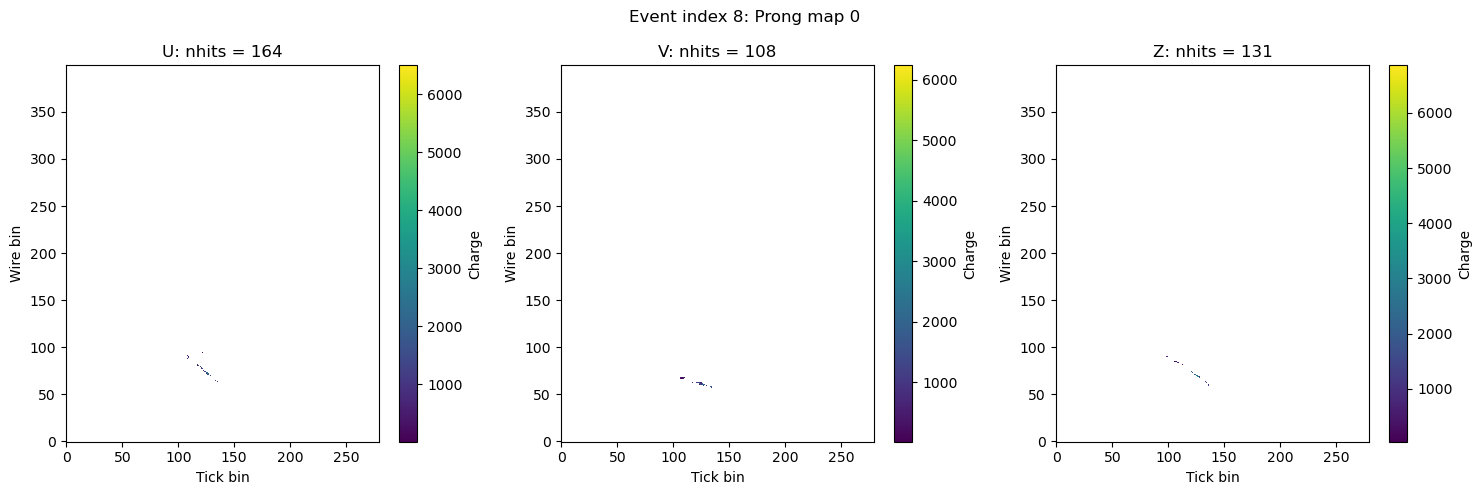

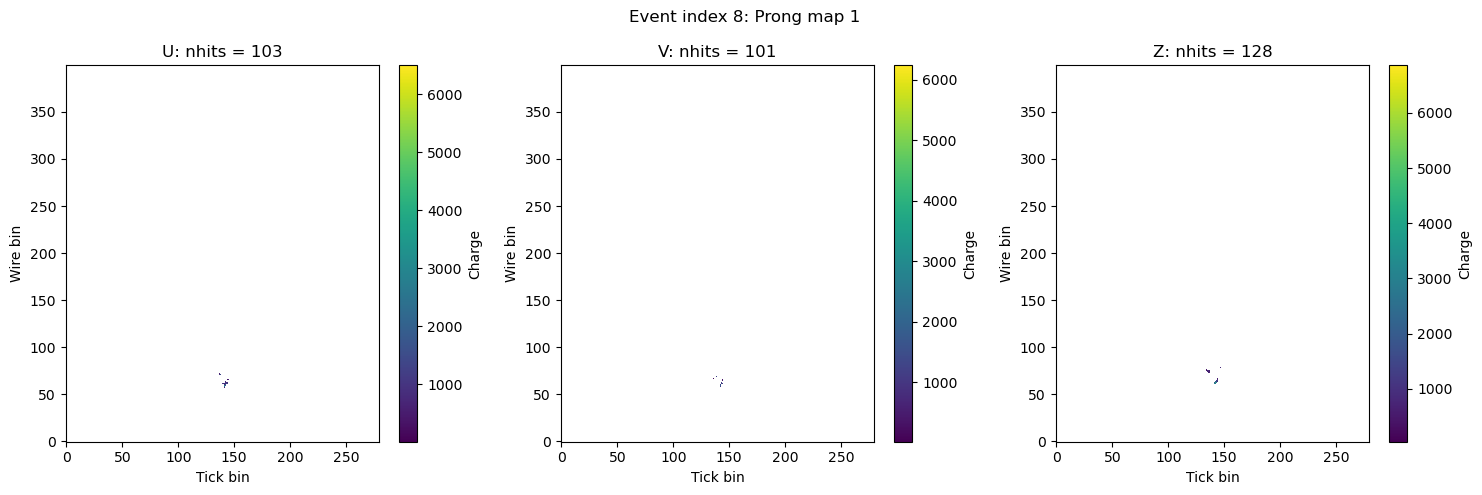

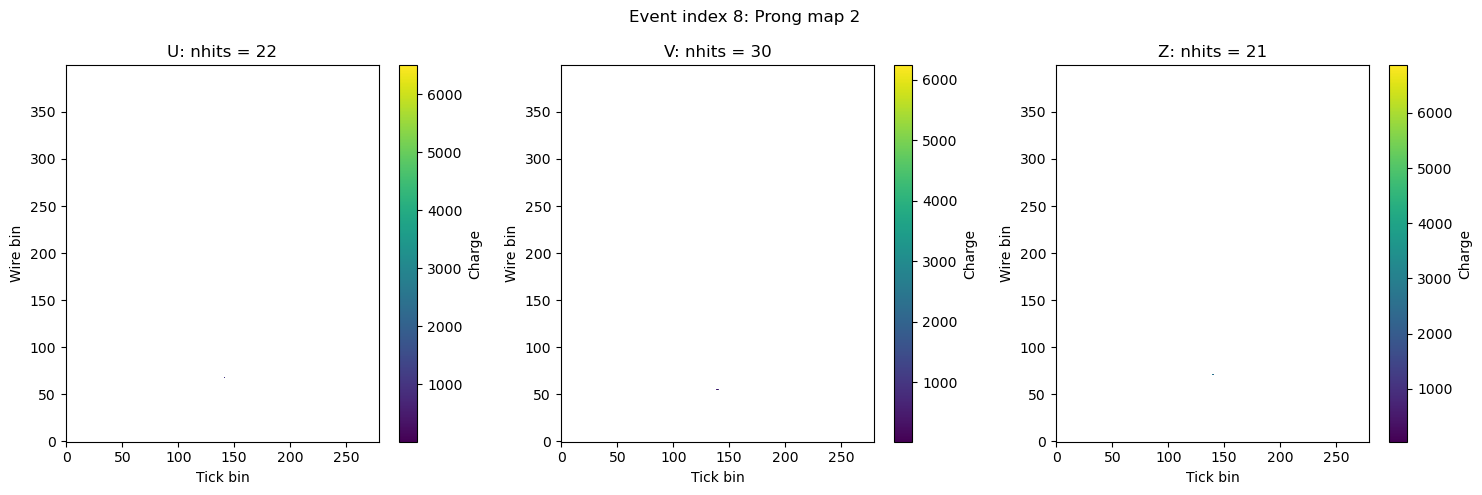

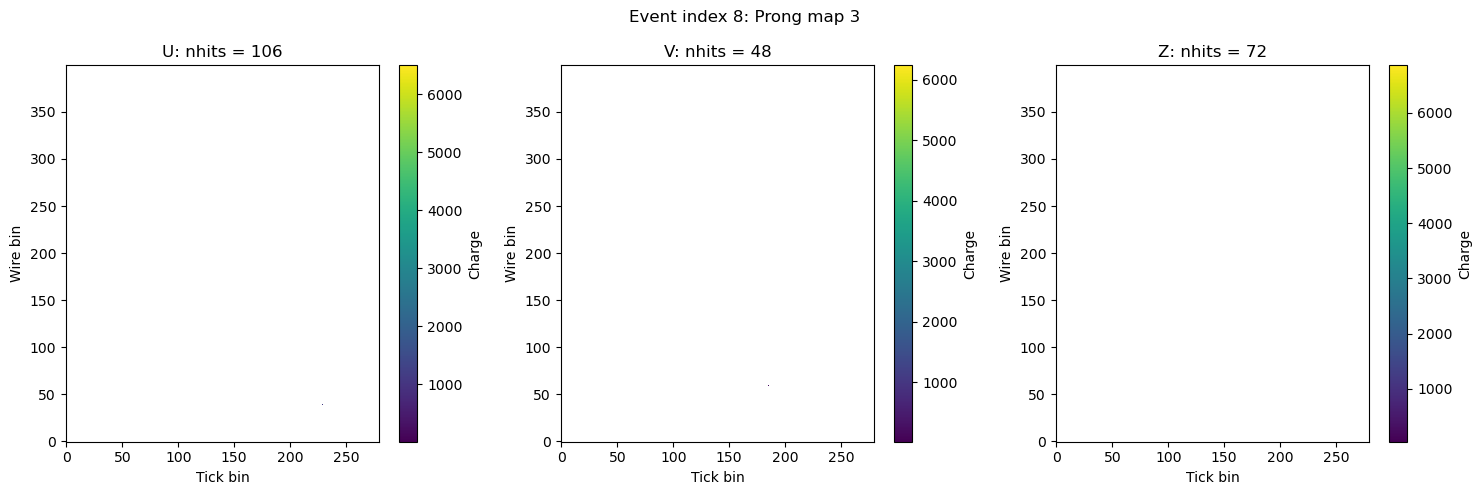

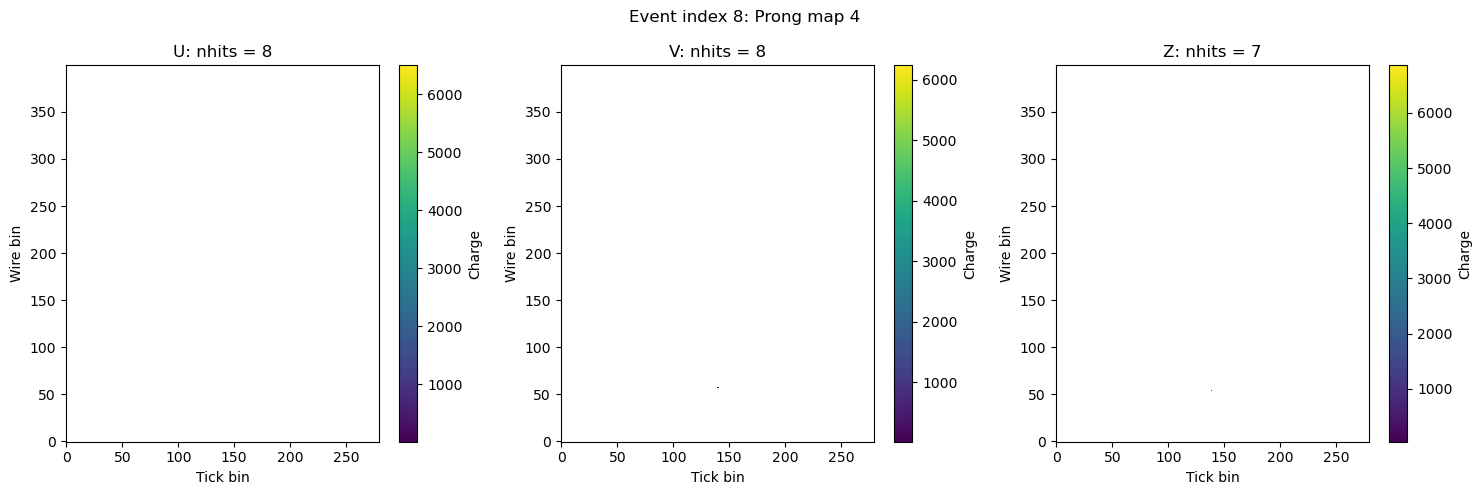

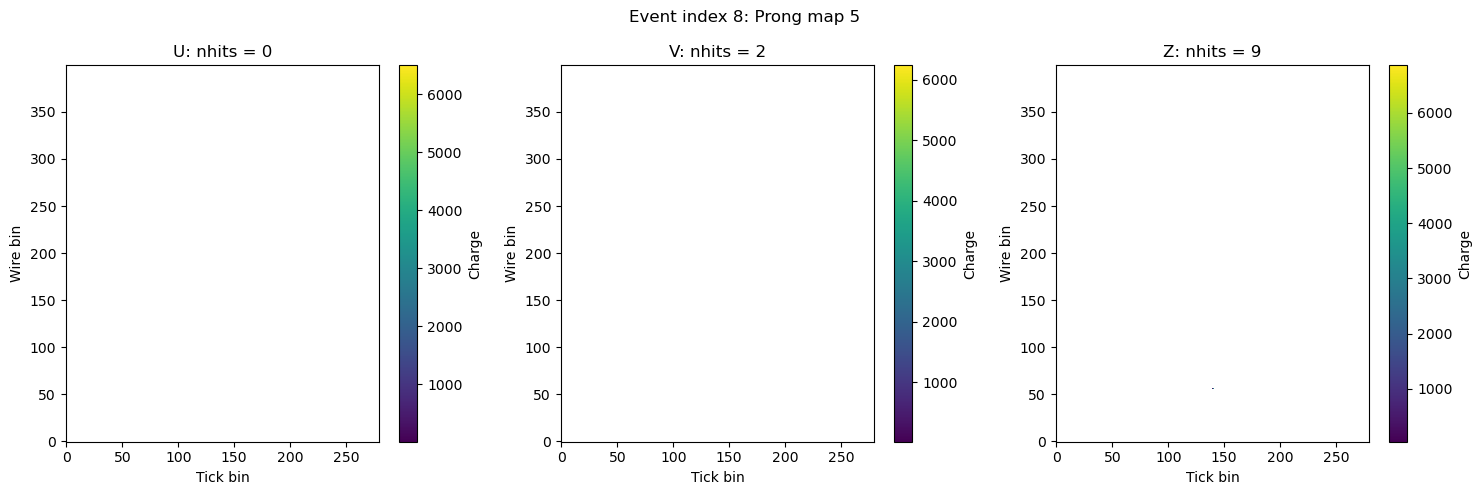

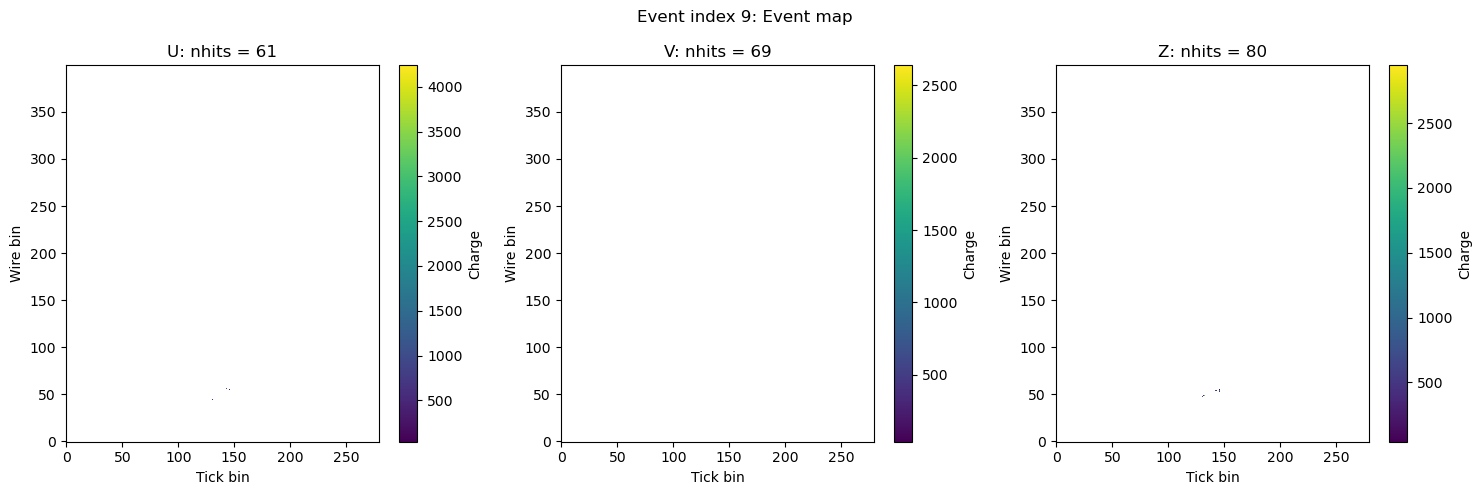

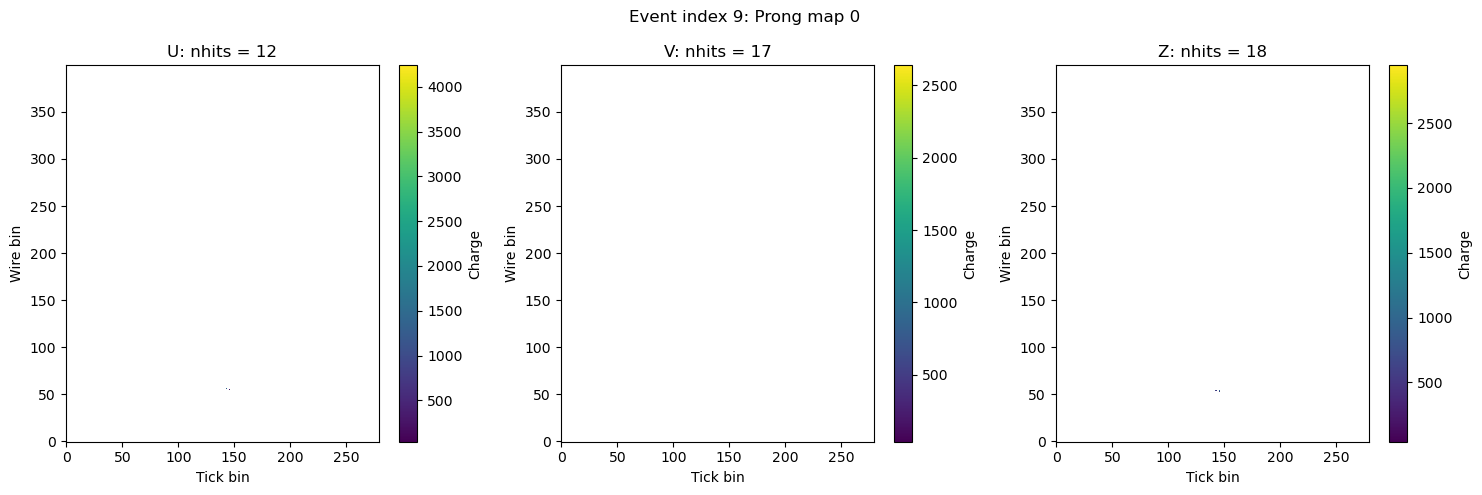

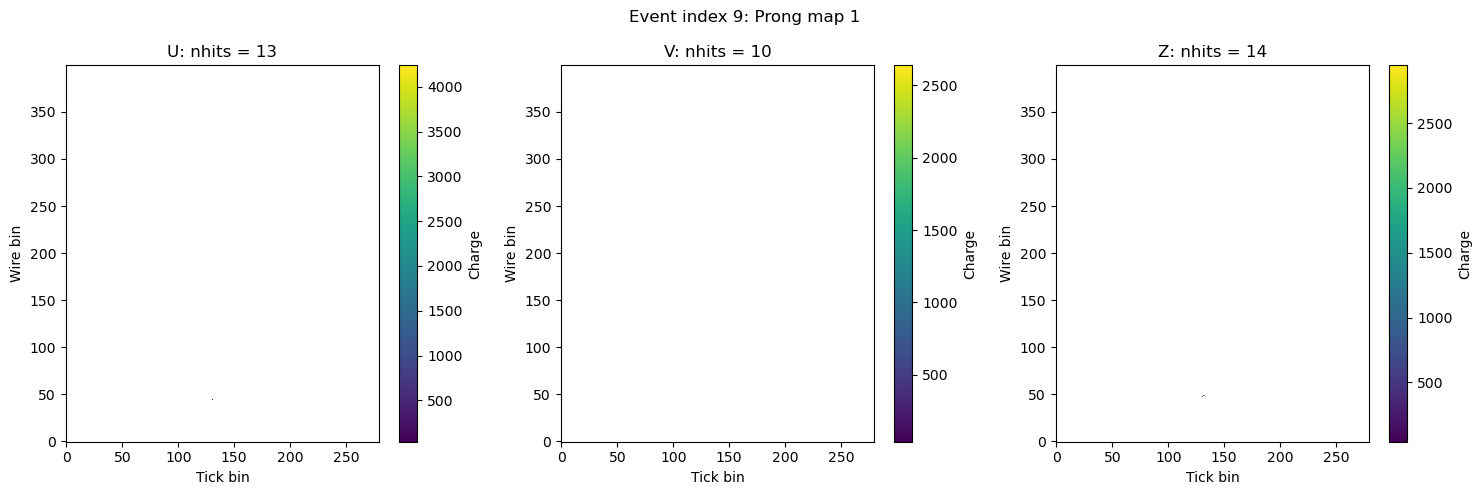

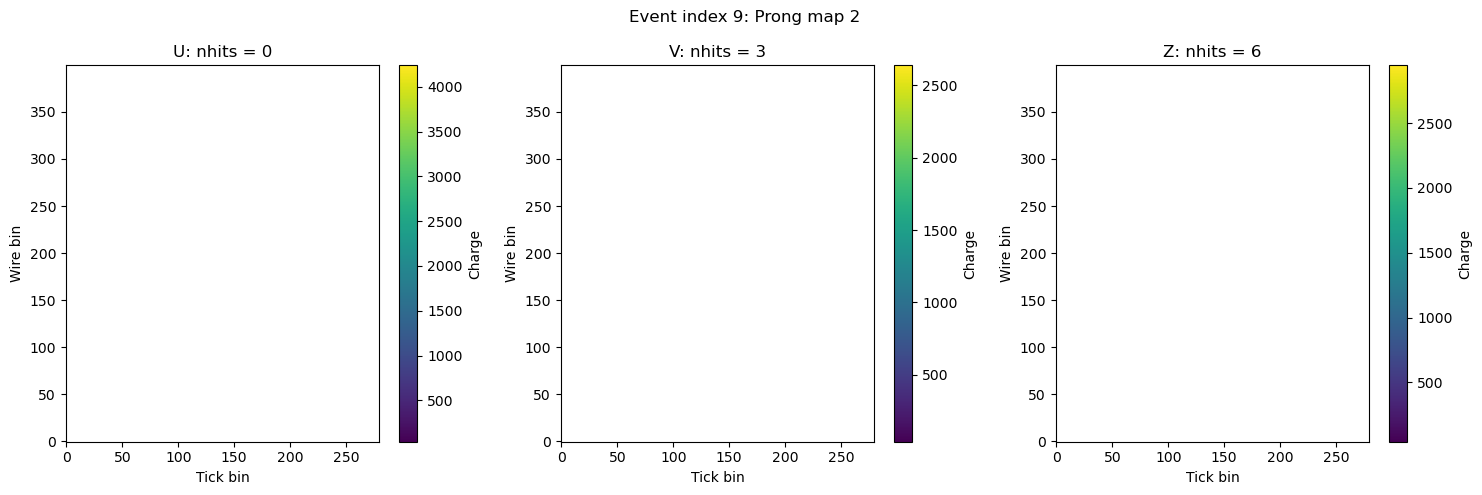

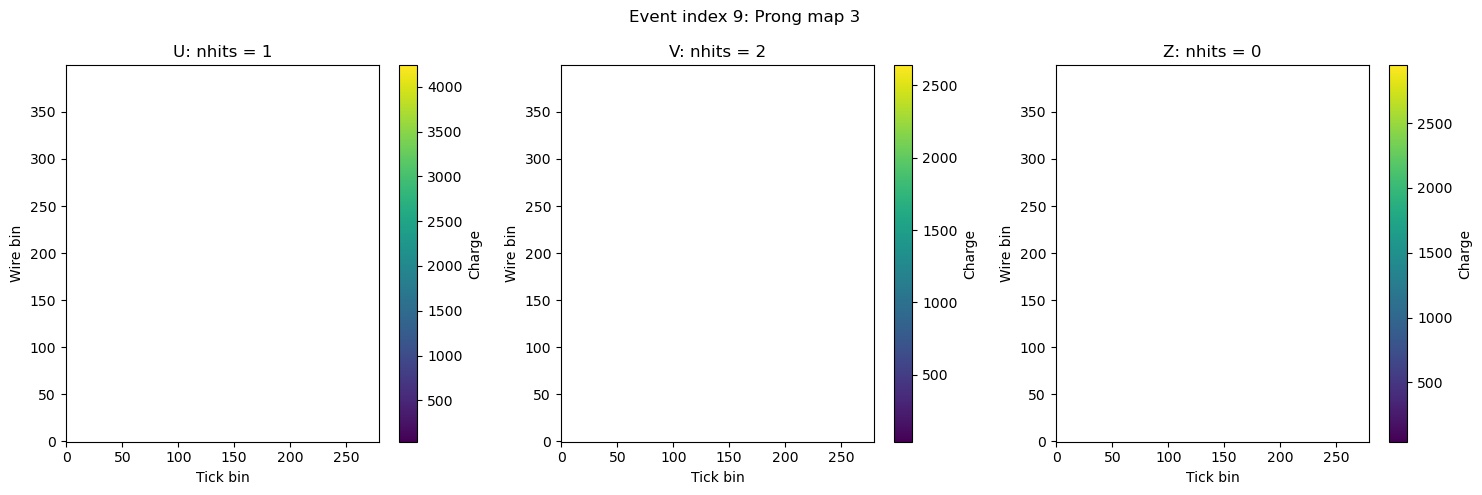

In [94]:
# Read the saved sparse maps and display ten events. IDX is zero-based.
import matplotlib.pyplot as plt

IDX = 0


def plot_pixel_maps(output_path, event_index):
    with h5py.File(output_path, "r") as saved:
        num_events = len(saved["event_target"])
        if not 0 <= event_index < num_events:
            raise ValueError(f"IDX must be between 0 and {num_events - 1}")

        for kind in ("event", "prong"):
            start, end = saved[f"{kind}_compressed_index"][event_index]
            coordinates = saved[f"{kind}_pixels_coordinates"][start:end]
            values = saved[f"{kind}_pixels_values"][start:end]
            shape = tuple(saved[f"{kind}_pixels_shape"][:])
            images = np.zeros(shape, dtype=np.float32)
            for plane in range(shape[1]):
                images[coordinates[:, 0], plane, coordinates[:, 1], coordinates[:, 2]] = values[:, plane]

            if kind == "event":
                # Reuse each event plane's color scale for all its prong maps.
                color_limits = []
                for pixels in images[0]:
                    nonzero = pixels[pixels != 0]
                    color_limits.append((float(nonzero.min()), float(nonzero.max())) if nonzero.size else (0.0, 1.0))

            map_indices = [0] if kind == "event" else np.flatnonzero(saved["prong_mask"][event_index])
            for map_index in map_indices:
                fig, axes = plt.subplots(1, 3, figsize=(15, 5))
                title = "Event map" if kind == "event" else f"Prong map {map_index}"
                fig.suptitle(f"Event index {event_index}: {title}")
                for plane, ax in enumerate(axes):
                    pixels = images[map_index, plane]
                    image = ax.imshow(np.ma.masked_equal(pixels, 0), origin="lower", aspect="auto", cmap="viridis",
                                      vmin=color_limits[plane][0], vmax=color_limits[plane][1])
                    ax.set_title(f"{'UVZ'[plane]}: nhits = {np.count_nonzero(pixels)}")
                    ax.set_xlabel("Tick bin")
                    ax.set_ylabel("Wire bin")
                    fig.colorbar(image, ax=ax, label="Charge")
                fig.tight_layout()
                plt.show()


for event_index in range(IDX, IDX + 10):
    plot_pixel_maps(OUTPUT_FILE, event_index)
